In [1]:
# ---- Device: must run before anything imports jax ----
from devices import use_device
use_device("auto")      # "auto" | "gpu" | "cpu"  (restart the kernel to switch)

import os
# os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false") # If sharing GPU with other processes
os.environ.setdefault("XLA_PYTHON_CLIENT_MEM_FRACTION", "0.2") # If not set, JAX automatically grabs 75% of the GPU's total memory, which can be excessive
# os.environ["XLA_FLAGS"] = (os.environ.get("XLA_FLAGS", "") + " --xla_gpu_deterministic_ops=true").strip() #force deterministic computation on GPU
import jax, numpyro
import jax.numpy as jnp
import numpy as np
print("JAX:", jax.__version__)
print(jax.default_backend())   # 'gpu' or 'cpu': where JAX runs things by default
print(jax.devices())           # e.g. [CudaDevice(id=0)] for the GPU, or 8 CpuDevices
print("local device count:", jax.local_device_count())

from model import (
    setup_model,
    make_orthogonal_poly_log_sed,
    running_power_law_log_sed,
)
from data import (
    prepare_burst,
)
from run import (
    iterative_pulse_fit,
)
from results import (
    save_run,
)
from plotting import (
    plot_burst_TD,
    plot_burst_FD,
    model_from_draw,
    plot_fit_TD,
)

from pathlib import Path

FRBayes: running on the GPU


/arc/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


JAX: 0.11.2
gpu
[CudaDevice(id=0)]
local device count: 1


In [2]:
# from numpyro.contrib.nested_sampling import NestedSampler   # jaxns switches JAX to float64 on this import

758 good channels -> 47 blocks of 16 (6 dropped); block span median 7.422 MHz, max 37.500 MHz
noise estimated from 796 of 3983 time bins (first 20% of the segment)
Fourier truncation: keeping 30 of 1992 bins (up to 0.7 kHz of 48.8 kHz)
weighted mean frequency 572.3 MHz, reference frequency 546.5 MHz
burst data shape = (47, 30)
rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


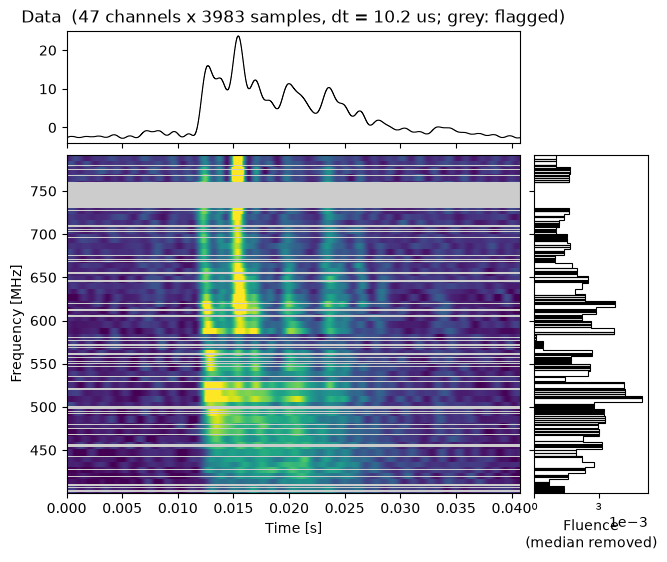

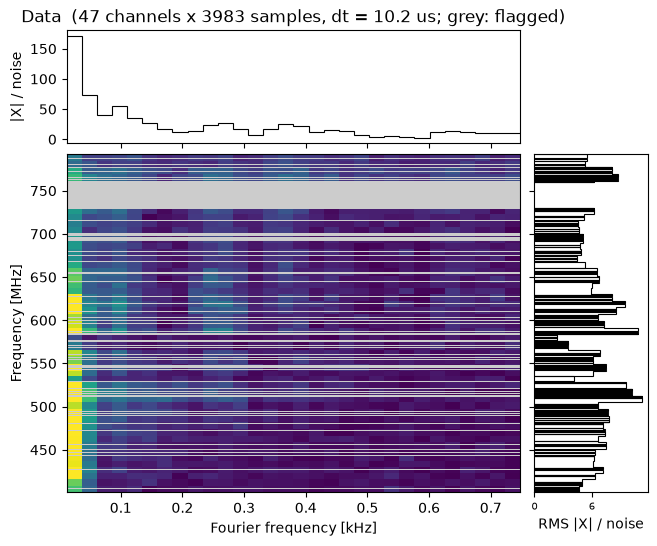

In [21]:
PROJECT  = Path("/arc/home/hsiegel/FRBayes")

# event_id = "22310619_BB" #Multi-pulse, 3 pulses
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# "22310619_BB"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=8,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

event_id = "27687783_BB" #Multi-pulse, many
data_path = PROJECT / "data" / f"event_{event_id}.npz"
burst = prepare_burst(
    path=data_path,
    n_avg=16,                # frequency channels averaged per block
    fd_downsample=64,        # downsampling factor of high frequency FD bins
    toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
    noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
    verbose=True,
)

# event_id = "23438043_BB" # Single-pulse, Narrow SED with scatter
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=8,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

# event_id = "22154974_BB" # Single-pulse, Broadband with scatter
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=8,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

# How the data were dedispersed before FRBayes; save_run refuses to save without both
dm_dedispersion = None          # pc cm^-3 (fill in)
dedispersion_ref_freq = None    # MHz the channels were aligned to; np.inf for infinite frequency (fill in)

out_path  = PROJECT / "runs" / f"event_{event_id}.nc"
out_path.parent.mkdir(parents=True, exist_ok=True)     # create runs/ if it doesn't exist

print("burst data shape =",burst.data_fd.shape)
plot_burst_TD(burst);                                          # data, in time
plot_burst_FD(burst);                                          # data, in Fourier space

# Jaxns slice nested sample

In [4]:
# import time
# import numpy as np
# import jax
# import numpyro.distributions as dist
# from model import setup_model, running_power_law_log_sed
# from run import set_priors
# from likelihood import FD_gaussianlikelihood

# constants_dict = {
#     "freq_channels_ref": burst.freq_channels_ref,
#     "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
#     "channel_width": burst.channel_width,
#     "det_response": 1.0,           # beam response, set to 1 if not used
# }
# single_pulse_fn = setup_model(
#     constants_dict=constants_dict,
#     freqs_channels=burst.freq_channels,
#     times=burst.times,
#     sed_fn=running_power_law_log_sed,
#     fourier_freqs=burst.fourier_freqs,
# )

# # the same priors and likelihood arguments the 1-pulse ITFit step uses
# priors = set_priors(burst, single_pulse_fn, 1, s_opt=100.0,
#                     gamma=dist.Uniform(-10.0, 200.0), beta=dist.Uniform(-200.0, 10.0))
# model_kwargs = dict(data_fd=burst.data_fd, sigma_noise_fd=burst.sigma_noise_fd, n_pulses=1, priors=priors,
#                     single_pulse_fn=single_pulse_fn, spectral_coeff_map=None, shared_params=("DM", "tau_ref"),
#                     ordered_times=False, repulsion={})

# ns = NestedSampler(FD_gaussianlikelihood, constructor_kwargs=dict(max_samples=1e6))   # default: 25 live points per parameter
# t0 = time.time()
# ns.run(jax.random.PRNGKey(2), **model_kwargs)
# print(f"nested sampling: {time.time() - t0:.0f} s")
# ns.print_summary()

In [5]:
import time
import jax
import numpyro.distributions as dist
from run import set_priors
from likelihood import FD_gaussianlikelihood
import numpyro.distributions as dist


constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
    "channel_width": burst.channel_width,
    "det_response": 1.0,           # beam response, set to 1 if not used
}
single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=running_power_law_log_sed,
    fourier_freqs=burst.fourier_freqs,
)


N_PULSES = 4
priors = set_priors(burst, single_pulse_fn, N_PULSES, s_opt=100.0,
                    gamma=dist.Uniform(-10.0, 200.0), beta=dist.Uniform(-200.0, 10.0))
model_kwargs = dict(data_fd=burst.data_fd, sigma_noise_fd=burst.sigma_noise_fd, n_pulses=N_PULSES, priors=priors,
                    single_pulse_fn=single_pulse_fn, spectral_coeff_map=None, shared_params=("DM", "tau_ref"),
                    ordered_times=False, repulsion={})

ns = NestedSampler(FD_gaussianlikelihood,
                   constructor_kwargs=dict(max_samples=1e6, verbose=False))     # 25 live points per parameter (550)
t0 = time.time()
ns.run(jax.random.PRNGKey(2), **model_kwargs)
print(f"nested sampling, {N_PULSES} pulses: {time.time() - t0:.0f} s")
ns.print_summary()

prior being set with bounds:
sigma_min = 2.6890819021378463e-05 
sigma_max = 0.0014643199911006377 
tau_ref_min = 0.0 
tau_ref_max = 0.0011280246028912404
mean_arrival_time: Uniform(low=0, high=0.00877568)
DM: Uniform(low=-0.234355, high=0.234355)
sigma: LogUniform(low=2.68908e-05, high=0.00146432)
tau_ref: Uniform(low=0, high=0.00112802)
A_snr: HalfNormal(scale=100)
gamma: Uniform(low=-10, high=200)
beta: Uniform(low=-200, high=10)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


INFO:jaxns:Number of Markov-chains set to: 550


sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
nested sampling, 4 pulses: 1125 s
--------
Termination Conditions:
Small remaining evidence
--------
likelihood evals: 20068033
samples: 37950
phantom samples: 0
likelihood evals / sample: 528.8
phantom fraction (%): 0.0%
--------
logZ=-3802.74 +- 0.42
max(logL)=-3723.86
H=-66.73
ESS=2041
--------
A[#]: mean +- std.dev. | 10%ile / 50%ile / 90%ile | MAP est. | max(L) est.
A[0]: 0.000157 +- 2.4e-05 | 0.000127 / 0.000157 / 0.000186 | 0.000152 | 0.000152
A[1]: 3e-15 +- 1.4e-14 | 0.0 / 0.0 / 5e-15 | 2.84e-13 | 2.84e-13
A[2]: 1.5e-13 +- 5.1e-13 | 0.0 / 0.0 / 4.2e-13 | 7.5e-13 | 7.5e-13
A[3]: 0.0001134 +- 5.4e-06 | 0.0001065 / 0.0001132 / 0.000120

# maxL itfit

In [9]:
import numpy as np
import numpyro.distributions as dist
from model import setup_model, running_power_law_log_sed
from maxL_itfit import maxL_iterative_pulse_fit
from plotting import model_from_draw, plot_fit_TD

In [22]:
constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
    "channel_width": burst.channel_width,
    "det_response": 1.0,           # beam response, set to 1 if not used
}
single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=running_power_law_log_sed,
    fourier_freqs=burst.fourier_freqs,
)

prior being set with bounds:
sigma_min = 0.00021637602005188298 
sigma_max = 0.006797653292020793 
tau_ref_min = 0.0 
tau_ref_max = 0.0061241657049724944
maxL_iterative_pulse_fit: snr_min 8, accept a pulse if ln L rises by >= 37 (snr_min^2 / 2 + 5 parameters), minimum box width 5 channels, up to 15 pulses, seed 2, tau profile over 8 values from 0.1 dt plus 0.001 dt
prior being set with bounds:
sigma_min = 0.00021637602005188298 
sigma_max = 0.006797653292020793 
tau_ref_min = 0.0 
tau_ref_max = 0.0061241657049724944
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR u

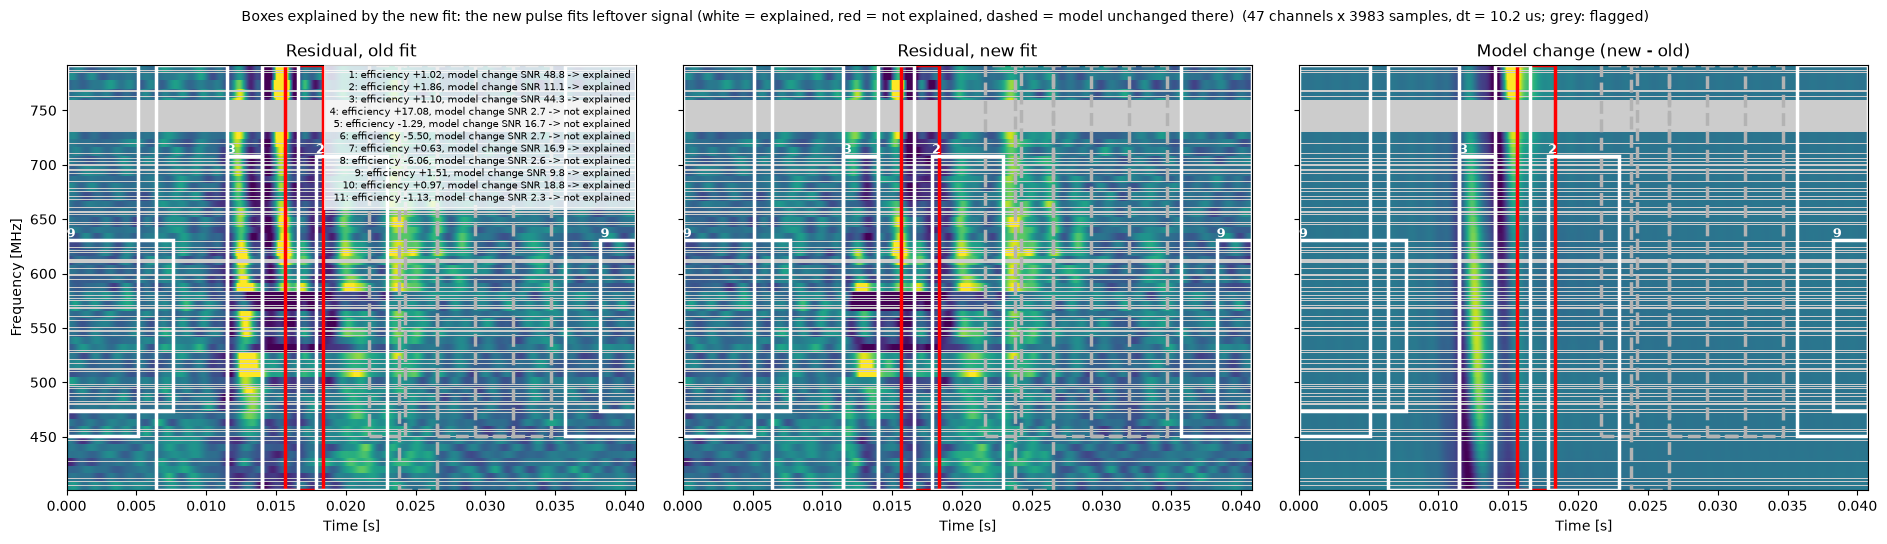

1 -> 2 pulses: delta ln L = 2426.6 (need 37), explains leftover signal: True -> accept
Residual test (tolerating 20% model error): ADD A PULSE (p = 0 after 22040 boxes; min_snr 8)
  11034 boxes significant on their own, making 11 separate feature(s):
    15.29-25.49 ms, 405-704 MHz: unexplained SNR 68.5 (residual 72.1, model 111.3), centre 19.82 ms, width 3.71 ms
    21.67-26.77 ms, 405-789 MHz: unexplained SNR 51.4 (residual 52.4, model 51.2), centre 25.50 ms, width 1.96 ms
    12.92-18.35 ms, 405-789 MHz: unexplained SNR 64.5 (residual 70.0, model 135.7), centre 15.15 ms, width 0.45 ms
    11.56-14.28 ms, 455-789 MHz: unexplained SNR 40.5 (residual 46.8, model 117.5), centre 12.78 ms, width 0.94 ms
    26.51-29.23 ms, 405-704 MHz: unexplained SNR 25.3 (residual 26.1, model 30.9), centre 28.67 ms, width 0.47 ms
    7.65-12.75 ms, 516-588 MHz: unexplained SNR 23.7 (residual 26.8, model 61.8), centre 10.51 ms, width 1.06 ms
    0.00-10.20 ms + 40.11-40.79 ms (wraps), 455-789 MHz: unexpl

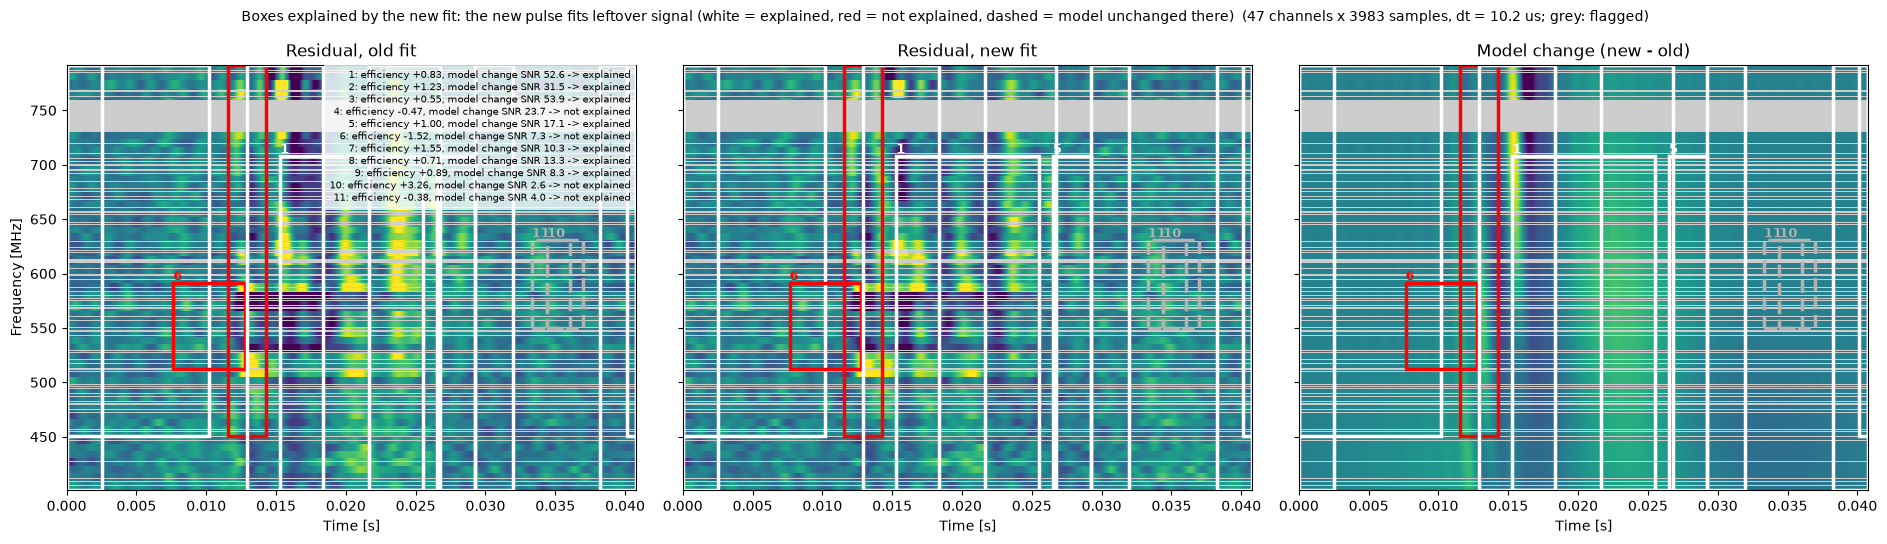

2 -> 3 pulses: delta ln L = 2576.9 (need 37), explains leftover signal: True -> accept
Residual test (tolerating 20% model error): ADD A PULSE (p = 0 after 22040 boxes; min_snr 8)
  9468 boxes significant on their own, making 11 separate feature(s):
    17.84-22.94 ms, 405-789 MHz: unexplained SNR 40.5 (residual 40.5, model 7.4), centre 20.37 ms, width 1.91 ms
    21.07-23.79 ms, 455-789 MHz: unexplained SNR 37.8 (residual 38.8, model 44.5), centre 23.12 ms, width 0.53 ms
    11.56-14.28 ms, 455-789 MHz: unexplained SNR 43.9 (residual 49.5, model 114.4), centre 12.59 ms, width 0.89 ms
    12.92-15.63 ms, 455-789 MHz: unexplained SNR 39.9 (residual 45.4, model 108.8), centre 14.84 ms, width 0.49 ms
    16.99-19.71 ms, 455-789 MHz: unexplained SNR 28.4 (residual 29.5, model 40.2), centre 17.48 ms, width 0.50 ms
    15.63-16.99 ms, 478-627 MHz: unexplained SNR 20.5 (residual 22.1, model 41.5), centre 16.30 ms, width 0.55 ms
    25.49-35.69 ms, 554-704 MHz: unexplained SNR 22.8 (residual 2

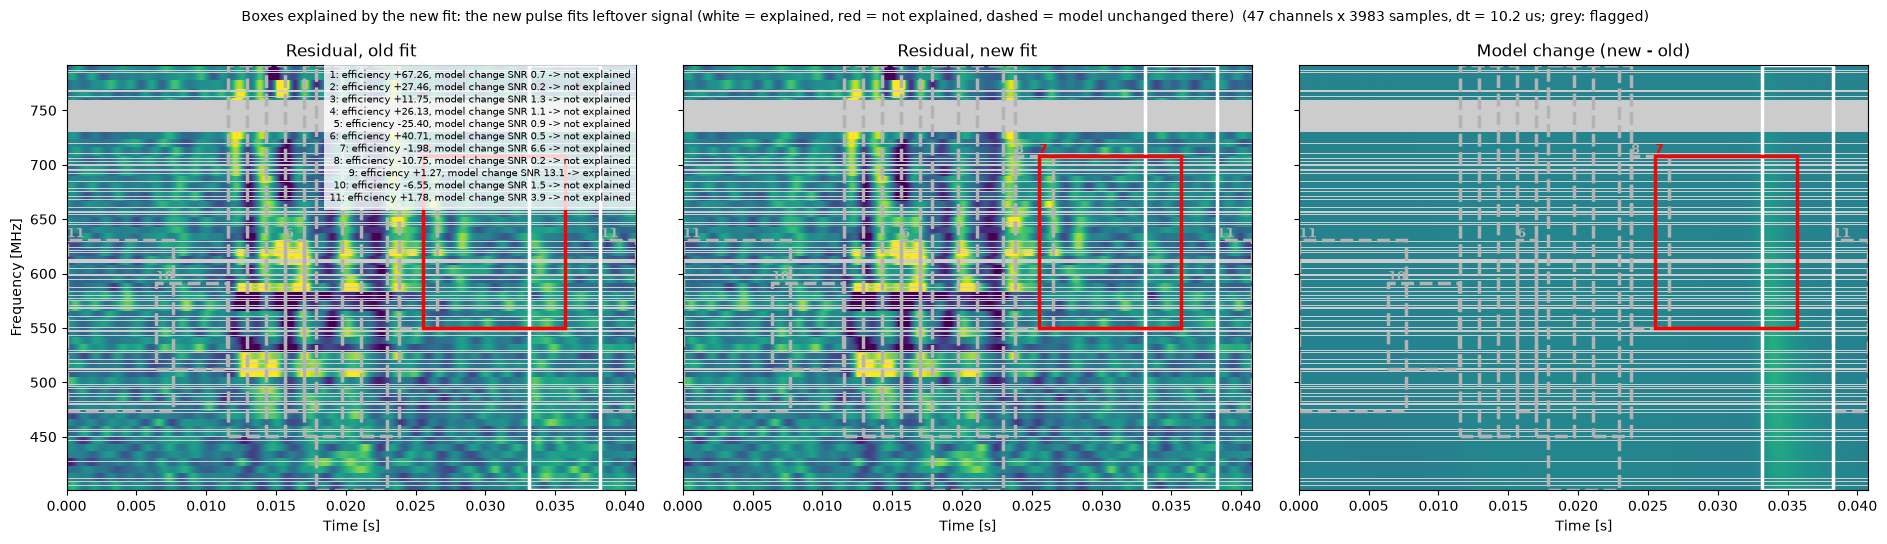

3 -> 4 pulses: delta ln L = 132.1 (need 37), explains leftover signal: True -> accept
Residual test (tolerating 20% model error): ADD A PULSE (p = 0 after 22040 boxes; min_snr 8)
  9192 boxes significant on their own, making 11 separate feature(s):
    17.84-22.94 ms, 405-789 MHz: unexplained SNR 40.1 (residual 40.2, model 7.9), centre 20.37 ms, width 1.92 ms
    21.07-23.79 ms, 455-789 MHz: unexplained SNR 37.8 (residual 38.8, model 44.6), centre 23.13 ms, width 0.53 ms
    11.56-14.28 ms, 455-789 MHz: unexplained SNR 43.7 (residual 49.3, model 114.8), centre 12.58 ms, width 0.89 ms
    12.92-15.63 ms, 455-789 MHz: unexplained SNR 39.4 (residual 45.1, model 109.4), centre 14.84 ms, width 0.49 ms
    16.57-19.12 ms, 455-789 MHz: unexplained SNR 27.2 (residual 27.9, model 31.5), centre 17.49 ms, width 0.50 ms
    25.49-35.69 ms, 554-704 MHz: unexplained SNR 24.8 (residual 26.5, model 46.8), centre 28.93 ms, width 2.89 ms
    15.63-16.99 ms, 478-627 MHz: unexplained SNR 20.3 (residual 21

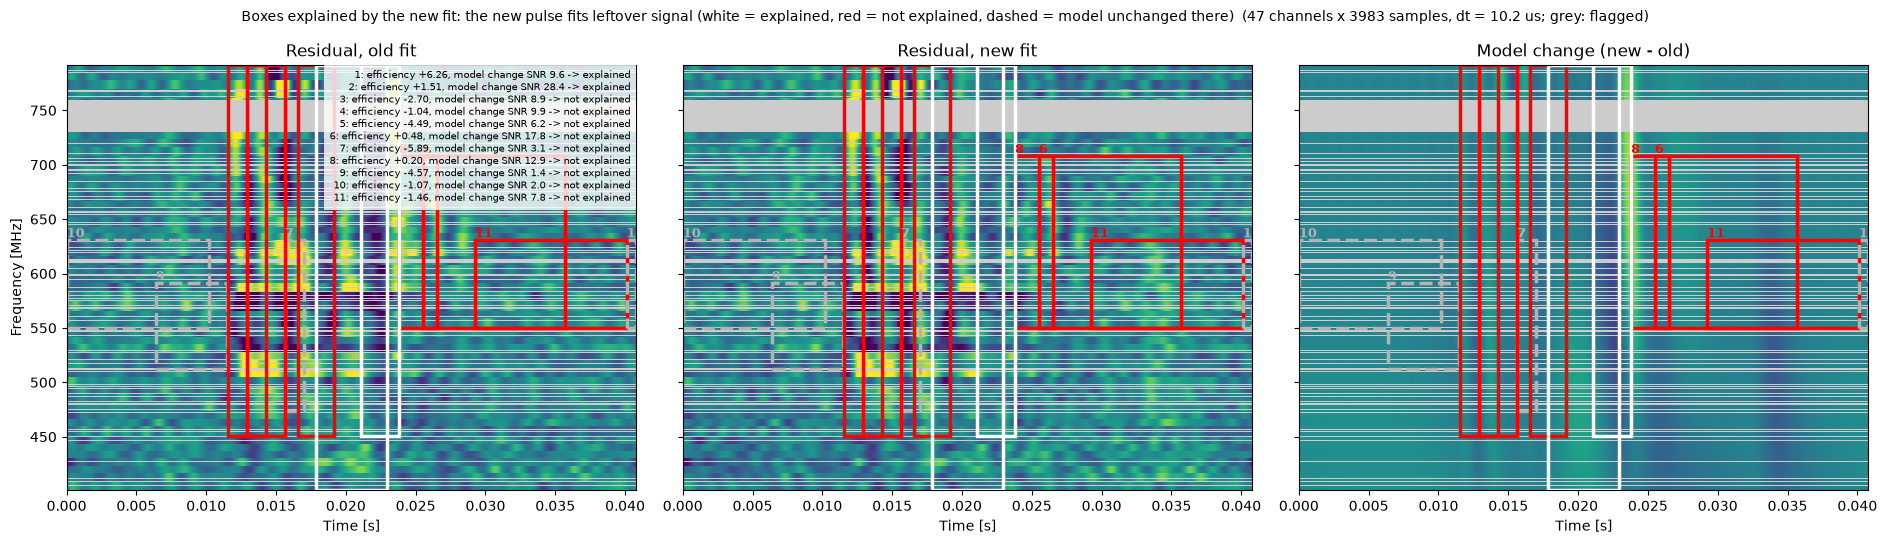

4 -> 5 pulses: delta ln L = 414.8 (need 37), explains leftover signal: True -> accept
Residual test (tolerating 20% model error): ADD A PULSE (p = 0 after 22040 boxes; min_snr 8)
  8949 boxes significant on their own, making 11 separate feature(s):
    17.84-22.94 ms, 405-789 MHz: unexplained SNR 32.0 (residual 32.1, model 13.8), centre 19.92 ms, width 1.77 ms
    11.56-14.28 ms, 455-789 MHz: unexplained SNR 46.2 (residual 51.4, model 112.7), centre 12.59 ms, width 0.89 ms
    16.57-19.12 ms, 455-789 MHz: unexplained SNR 30.3 (residual 30.9, model 28.1), centre 17.48 ms, width 0.50 ms
    12.92-15.63 ms, 455-789 MHz: unexplained SNR 40.6 (residual 46.2, model 109.9), centre 15.03 ms, width 0.54 ms
    15.63-16.99 ms, 455-789 MHz: unexplained SNR 25.6 (residual 28.9, model 67.4), centre 16.32 ms, width 0.54 ms
    23.79-29.23 ms, 554-704 MHz: unexplained SNR 20.9 (residual 22.8, model 45.8), centre 24.49 ms, width 0.53 ms
    25.49-35.69 ms, 554-704 MHz: unexplained SNR 20.8 (residual 2

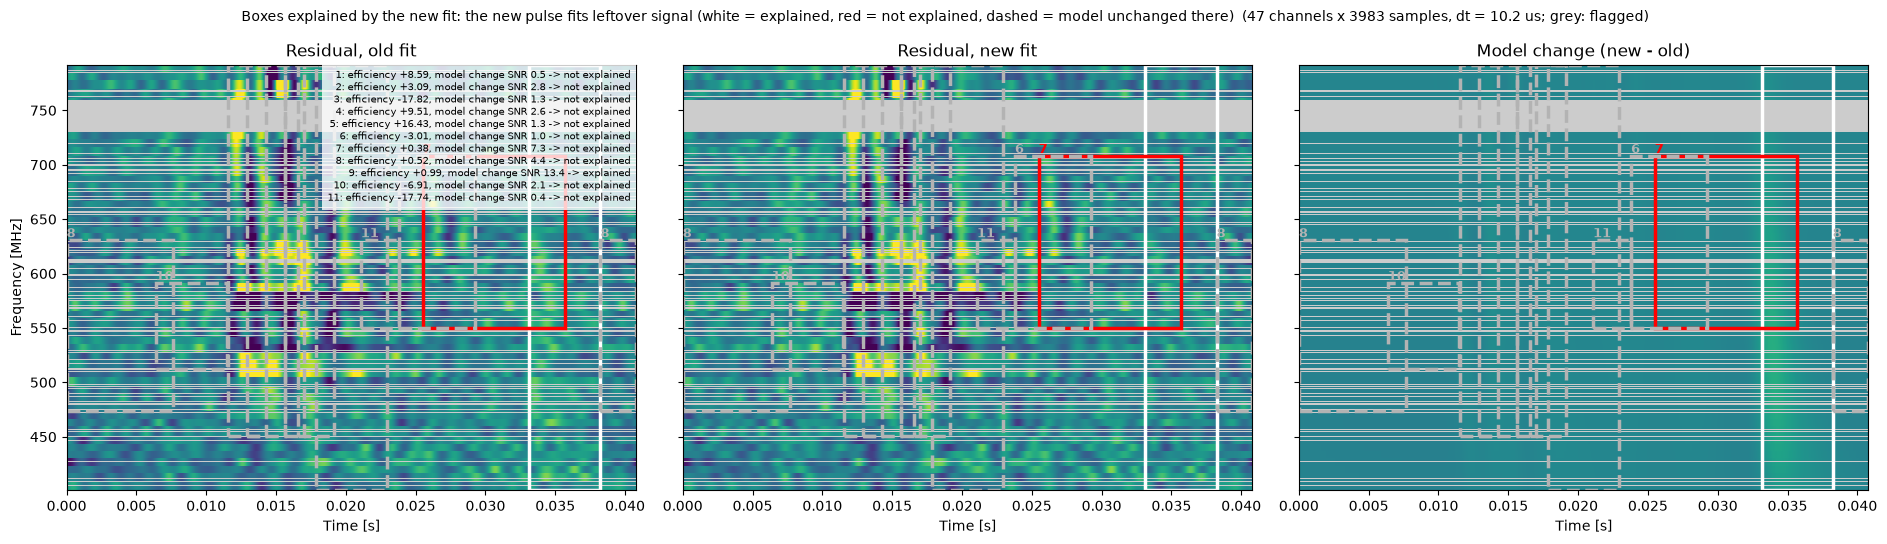

5 -> 6 pulses: delta ln L = 133.9 (need 37), explains leftover signal: True -> accept
Residual test (tolerating 20% model error): ADD A PULSE (p = 0 after 22040 boxes; min_snr 8)
  8746 boxes significant on their own, making 11 separate feature(s):
    17.84-22.94 ms, 405-789 MHz: unexplained SNR 31.9 (residual 32.1, model 13.9), centre 19.92 ms, width 1.77 ms
    11.56-14.28 ms, 455-789 MHz: unexplained SNR 45.9 (residual 51.2, model 113.2), centre 12.58 ms, width 0.89 ms
    16.57-19.12 ms, 455-789 MHz: unexplained SNR 30.8 (residual 31.3, model 28.6), centre 17.48 ms, width 0.50 ms
    12.92-15.63 ms, 455-789 MHz: unexplained SNR 39.7 (residual 45.5, model 110.9), centre 15.03 ms, width 0.54 ms
    15.63-16.99 ms, 455-789 MHz: unexplained SNR 25.1 (residual 28.4, model 66.6), centre 16.32 ms, width 0.54 ms
    23.79-29.23 ms, 554-704 MHz: unexplained SNR 21.0 (residual 22.8, model 45.2), centre 26.37 ms, width 1.48 ms
    26.51-31.95 ms, 554-704 MHz: unexplained SNR 17.5 (residual 1

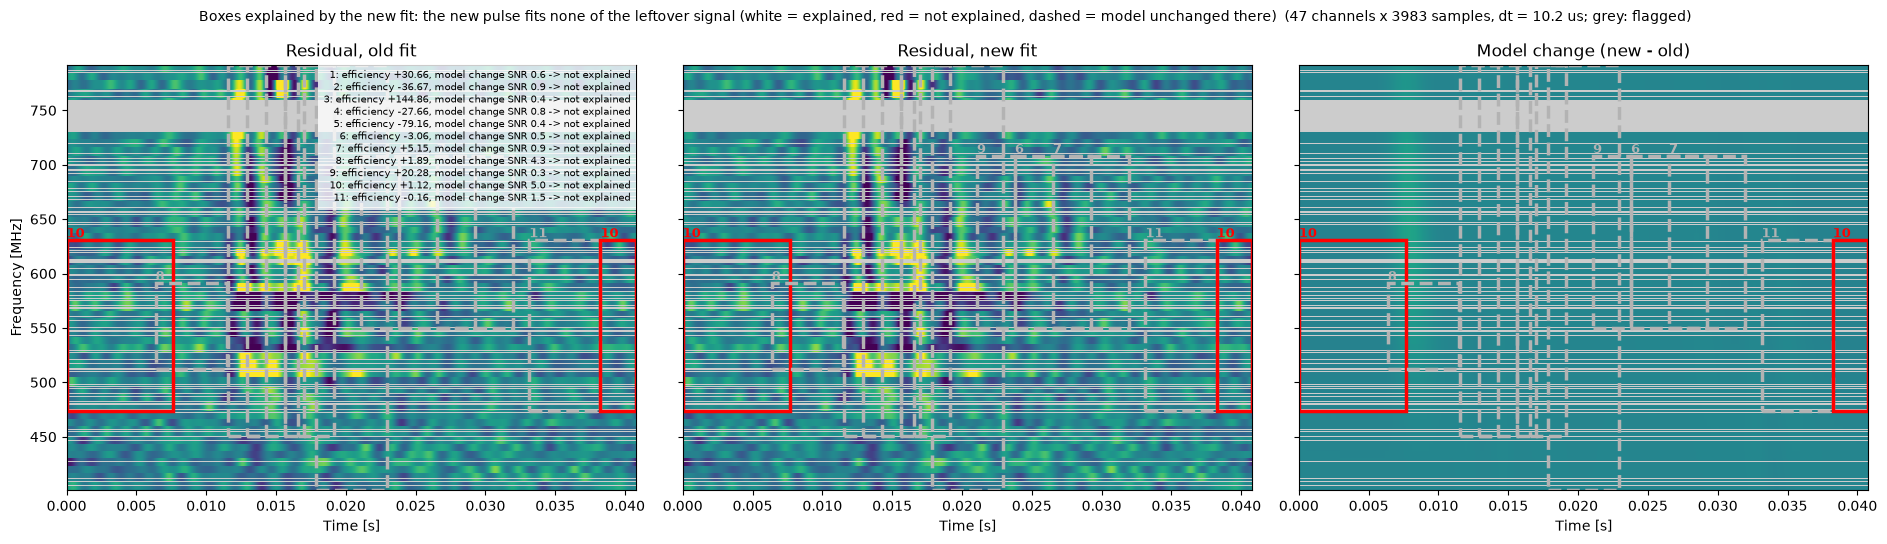

6 -> 7 pulses: delta ln L = 56.3 (need 37), explains leftover signal: False -> reject
final: 6 pulses (7-pulse fit rejected: it explains no flagged leftover signal); optimizer time 548 s
rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


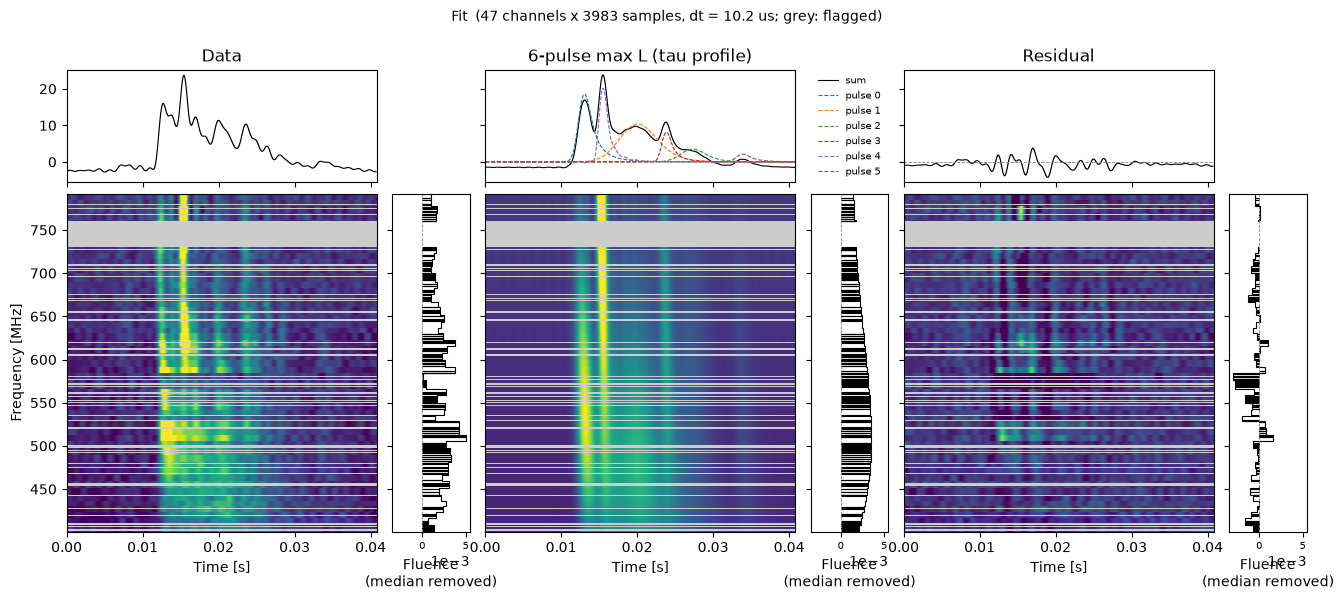

In [23]:
res_ml = maxL_iterative_pulse_fit(
    burst, single_pulse_fn,
    snr_min=8.0, n_max=5, num_starts=64, seed=2, plot_steps=True,
    tau_profile=8, tau_parallel=False,                      # 8 tau values, 5 us to the prior maximum
    prior_kwargs=dict(gamma=dist.Uniform(-10.0, 200.0), beta=dist.Uniform(-200.0, 10.0)),
    repulsion={},
    n_adam=1000,
    n_polish=500,
    n_bfgs=500,
)
M, M_pulses = model_from_draw(single_pulse_fn, res_ml["fit"]["post"], 0)
plot_fit_TD(burst, M, M_pulses, title_model=f"{res_ml['n_pulses']}-pulse max L (tau profile)");

In [12]:
stats = jax.devices()[0].memory_stats()
print(f"peak {stats['peak_bytes_in_use'] / 1e9:.2f} GB of {stats['bytes_limit'] / 1e9:.2f} GB")

peak 0.21 GB of 2.31 GB


# NUTS

prior being set with bounds:
sigma_min = 2.6890819453714833e-05 
sigma_max = 0.0014643199911006377 
tau_ref_min = 0.0 
tau_ref_max = 0.0011280245631210115
prior being set with bounds:
c1_min = -1.922094 
c1_max = 38.441883 
c2_min = -5.0560703 
c2_max = 0.25280353
iterative_pulse_fit: snr_min 8 (delta ELPD threshold 32), minimum box width 5 channels, up to 5 pulses
prior being set with bounds:
sigma_min = 2.6890819453714833e-05 
sigma_max = 0.0014643199911006377 
tau_ref_min = 0.0 
tau_ref_max = 0.0011280245631210115
prior being set with bounds:
c1_min = -1.922094 
c1_max = 38.441883 
c2_min = -5.0560703 
c2_max = 0.25280353
mean_arrival_time: Uniform(low=0, high=0.00877568)
DM: Uniform(low=-0.234355, high=0.234355)
sigma: LogUniform(low=2.68908e-05, high=0.00146432)
tau_ref: Uniform(low=0, high=0.00112802)
c1: Uniform(low=-1.92209, high=38.4419)
c2: Uniform(low=-5.05607, high=0.252804)
A_snr: HalfNormal(scale=100)
run_fit seed: 2
sampling the amplitude as A_snr (SNR units)
sampling th

  0%|          | 0/700 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


sample: 100%|██████████| 700/700 [00:43<00:00, 16.07it/s] 


group_chains: 64 chains -> 2 mode(s) (pairs linked where every R-hat < 1.1)
  mode 0: chains [0, 4, 15, 18, 27, 30, 38, 44, 45, 48, 49, 57], largest R-hat within 1.049
  mode 1: chains [1, 2, 3, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 16, 17, 19, 20, 21, 22, 23, 24, 25, 26, 28, 29, 31, 32, 33, 34, 35, 36, 37, 39, 40, 41, 42, 43, 46, 47, 50, 51, 52, 53, 54, 55, 56, 58, 59, 60, 61, 62, 63], largest R-hat within 1.086
  modes weighted by peak posterior:
  mode 0: peak log post +0.0, mean log-lik +0.0, weight 1.000 (stacking would give 0.755), 2400 draws from 12 chain(s)
  mode 1: peak log post -951.6, mean log-lik -948.5, weight 0.000 (stacking would give 0.245), 0 draws from 52 chain(s)
combine_chains: 2400 draws in all
Residual test (tolerating 20% model error): ADD A PULSE (p = 0 after 56240 boxes; min_snr 8)
  8682 boxes significant on their own, making 6 separate feature(s):
    3.16-3.71 ms, 404-686 MHz: unexplained SNR 41.4 (residual 41.4, model 2.6), centre 3.39 ms, width 0.39 ms
    3

  0%|          | 0/700 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


sample: 100%|██████████| 700/700 [03:28<00:00,  3.36it/s]


group_chains: 64 chains -> 7 mode(s) (pairs linked where every R-hat < 1.1)
  mode 0: chains [0, 1, 2, 3, 5, 6, 7, 8, 9, 10, 14, 16, 17, 18, 19, 24, 25, 26, 28, 30, 31, 32, 34, 35, 36, 38, 41, 42, 43, 44, 45, 48, 50, 52, 54, 55, 57, 58, 59, 60, 62, 63], largest R-hat within 1.103
  mode 1: chains [4, 20, 29], largest R-hat within 1.033
  mode 2: chains [22, 23, 37], largest R-hat within 1.030
  mode 3: chains [53]
  mode 4: chains [11, 12, 13, 15, 21, 27, 33, 39, 46, 49, 51, 56, 61], largest R-hat within 1.060
  mode 5: chains [47]
  mode 6: chains [40]
  modes weighted by peak posterior:
  mode 0: peak log post +0.0, mean log-lik +0.0, weight 1.000 (stacking would give 0.547), 8400 draws from 42 chain(s)
  mode 1: peak log post -686.8, mean log-lik -679.1, weight 0.000 (stacking would give 0.197), 0 draws from 3 chain(s)
  mode 2: peak log post -792.7, mean log-lik -789.7, weight 0.000 (stacking would give 0.059), 0 draws from 3 chain(s)
  mode 3: peak log post -843.1, mean log-lik -8

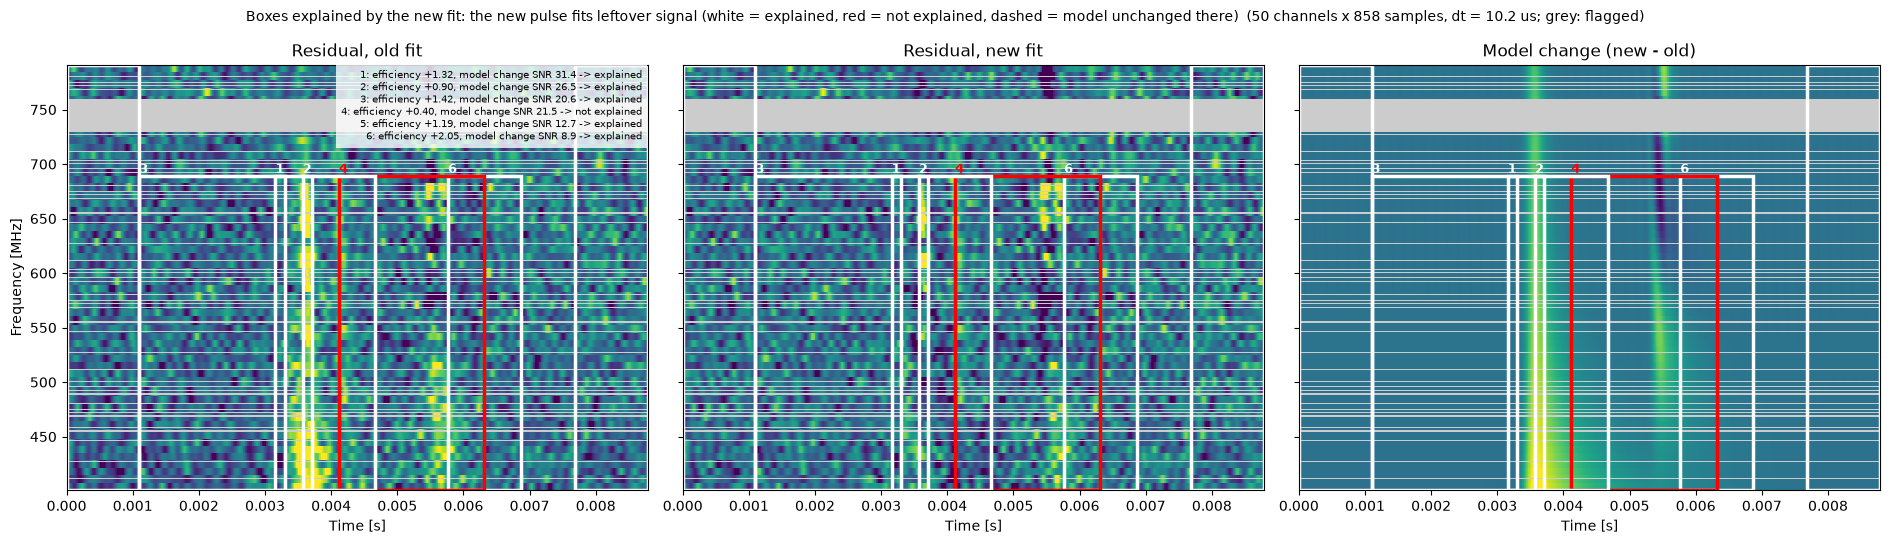

1 -> 2 pulses: delta ELPD = 812.6 (need 32.0), explains leftover signal: True -> accept
Residual test (tolerating 20% model error): ADD A PULSE (p = 4.4e-82 after 56240 boxes; min_snr 8)
  5019 boxes significant on their own, making 5 separate feature(s):
    4.12-6.31 ms, 404-788 MHz: unexplained SNR 33.9 (residual 35.8, model 57.6), centre 5.48 ms, width 0.39 ms
    3.29-3.97 ms, 404-686 MHz: unexplained SNR 21.5 (residual 22.5, model 33.1), centre 3.58 ms, width 0.10 ms
    5.49-7.69 ms, 404-788 MHz: unexplained SNR 27.0 (residual 28.4, model 45.6), centre 6.44 ms, width 0.34 ms
    3.63-4.31 ms, 404-686 MHz: unexplained SNR 17.8 (residual 18.2, model 20.5), centre 4.07 ms, width 0.06 ms
    0.00-3.29 ms + 7.69-8.79 ms (wraps), 404-788 MHz: unexplained SNR 24.0 (residual 25.1, model 37.2), centre 2.45 ms, width 0.77 ms
prior being set with bounds:
sigma_min = 2.6890819453714833e-05 
sigma_max = 0.0014643199911006377 
tau_ref_min = 0.0 
tau_ref_max = 0.0011280245631210115
prior being

  0%|          | 0/700 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


sample: 100%|██████████| 700/700 [05:04<00:00,  2.30it/s]


group_chains: 64 chains -> 13 mode(s) (pairs linked where every R-hat < 1.1)
  mode 0: chains [0, 9, 11, 14, 16, 18, 28], largest R-hat within 1.036
  mode 1: chains [1, 3, 5, 6, 13, 25, 56], largest R-hat within 1.029
  mode 2: chains [33]
  mode 3: chains [4, 7, 8, 31, 53, 58], largest R-hat within 1.043
  mode 4: chains [54]
  mode 5: chains [2, 10, 12, 15, 19, 20, 21, 22, 23, 24, 27, 29, 32, 34, 35, 36, 38, 39, 40, 41, 42, 43, 45, 46, 48, 49, 50, 52, 55, 57, 61, 62, 63], largest R-hat within 1.256
  mode 6: chains [17]
  mode 7: chains [47]
  mode 8: chains [30, 44], largest R-hat within 1.048
  mode 9: chains [26, 37], largest R-hat within 1.014
  mode 10: chains [51]
  mode 11: chains [59]
  mode 12: chains [60]
  modes weighted by peak posterior:
  mode 0: peak log post +0.0, mean log-lik +0.0, weight 1.000 (stacking would give 0.487), 1400 draws from 7 chain(s)
  mode 1: peak log post -167.1, mean log-lik -174.6, weight 0.000 (stacking would give 0.187), 0 draws from 7 chain(s)

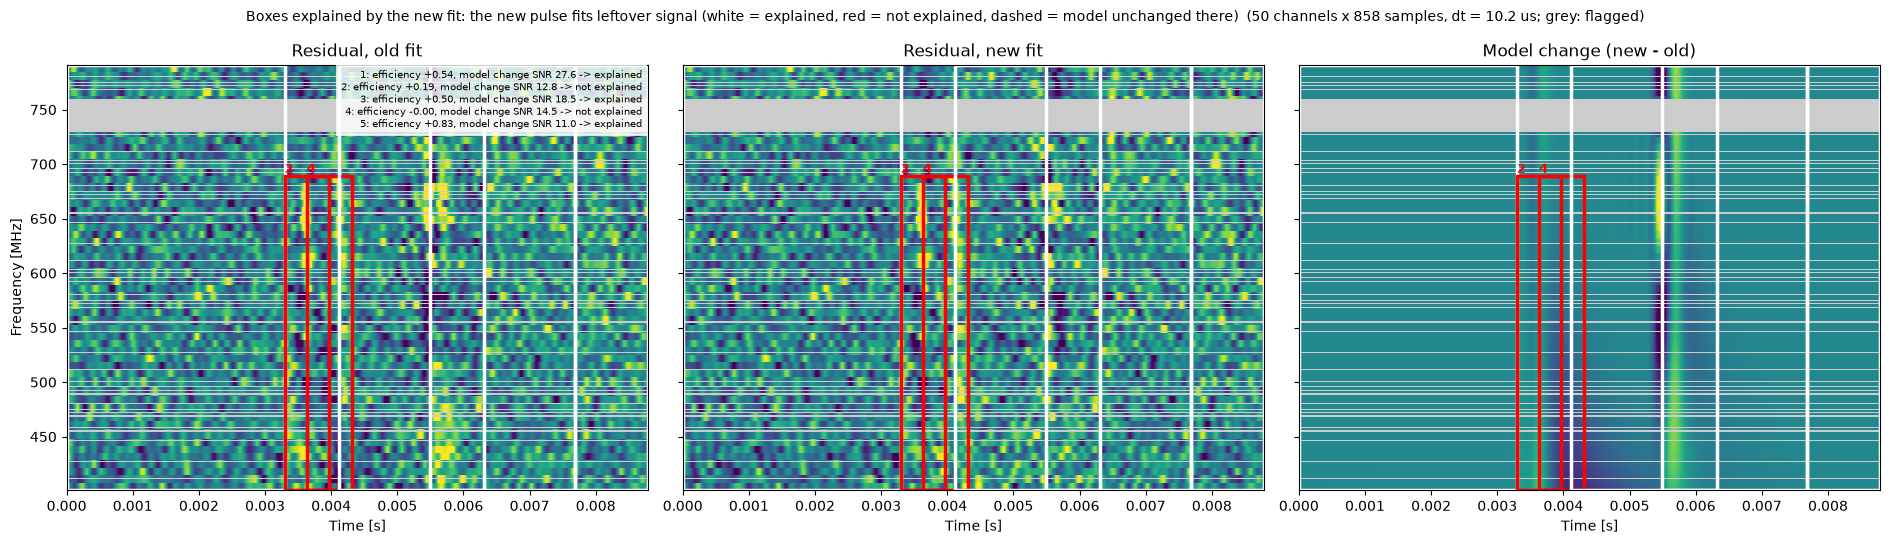

2 -> 3 pulses: delta ELPD = 262.7 (need 32.0), explains leftover signal: True -> accept
Residual test (tolerating 20% model error): ADD A PULSE (p = 3.7e-50 after 56240 boxes; min_snr 8)
  3251 boxes significant on their own, making 6 separate feature(s):
    3.16-3.71 ms, 476-788 MHz: unexplained SNR 19.3 (residual 19.9, model 25.0), centre 3.57 ms, width 0.10 ms
    3.63-4.31 ms, 404-788 MHz: unexplained SNR 18.9 (residual 19.4, model 23.9), centre 4.12 ms, width 0.10 ms
    5.49-5.66 ms, 476-788 MHz: unexplained SNR 13.7 (residual 14.7, model 25.8), centre 5.59 ms, width 0.06 ms
    2.47-3.57 ms, 404-686 MHz: unexplained SNR 16.1 (residual 17.0, model 27.2), centre 2.73 ms, width 0.70 ms
    5.15-5.49 ms, 404-686 MHz: unexplained SNR 13.2 (residual 15.0, model 36.0), centre 5.36 ms, width 0.14 ms
    6.17-6.50 ms, 476-788 MHz: unexplained SNR 11.4 (residual 11.5, model 8.1), centre 6.36 ms, width 0.15 ms
prior being set with bounds:
sigma_min = 2.6890819453714833e-05 
sigma_max = 0.

  0%|          | 0/700 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


sample: 100%|██████████| 700/700 [06:15<00:00,  1.86it/s]


group_chains: 64 chains -> 19 mode(s) (pairs linked where every R-hat < 1.1)
  mode 0: chains [2, 5, 8, 9, 12, 16, 19, 22, 25, 29, 31, 38, 51], largest R-hat within 1.048
  mode 1: chains [7]
  mode 2: chains [0, 1, 3, 6, 10, 13, 14, 15, 17, 20, 21, 26, 28, 30, 44, 50], largest R-hat within 1.049
  mode 3: chains [23]
  mode 4: chains [24]
  mode 5: chains [4, 11, 27], largest R-hat within 1.029
  mode 6: chains [18]
  mode 7: chains [40, 54, 55, 57], largest R-hat within 1.025
  mode 8: chains [59]
  mode 9: chains [37]
  mode 10: chains [42, 46, 47, 48, 49, 58, 60, 61, 62], largest R-hat within 1.131
  mode 11: chains [36]
  mode 12: chains [53]
  mode 13: chains [43, 56], largest R-hat within 1.085
  mode 14: chains [32]
  mode 15: chains [34, 41, 45, 52, 63], largest R-hat within 1.132
  mode 16: chains [39]
  mode 17: chains [35]
  mode 18: chains [33]
  modes weighted by peak posterior:
  mode 0: peak log post +0.0, mean log-lik +0.0, weight 0.650 (stacking would give 0.000), 371

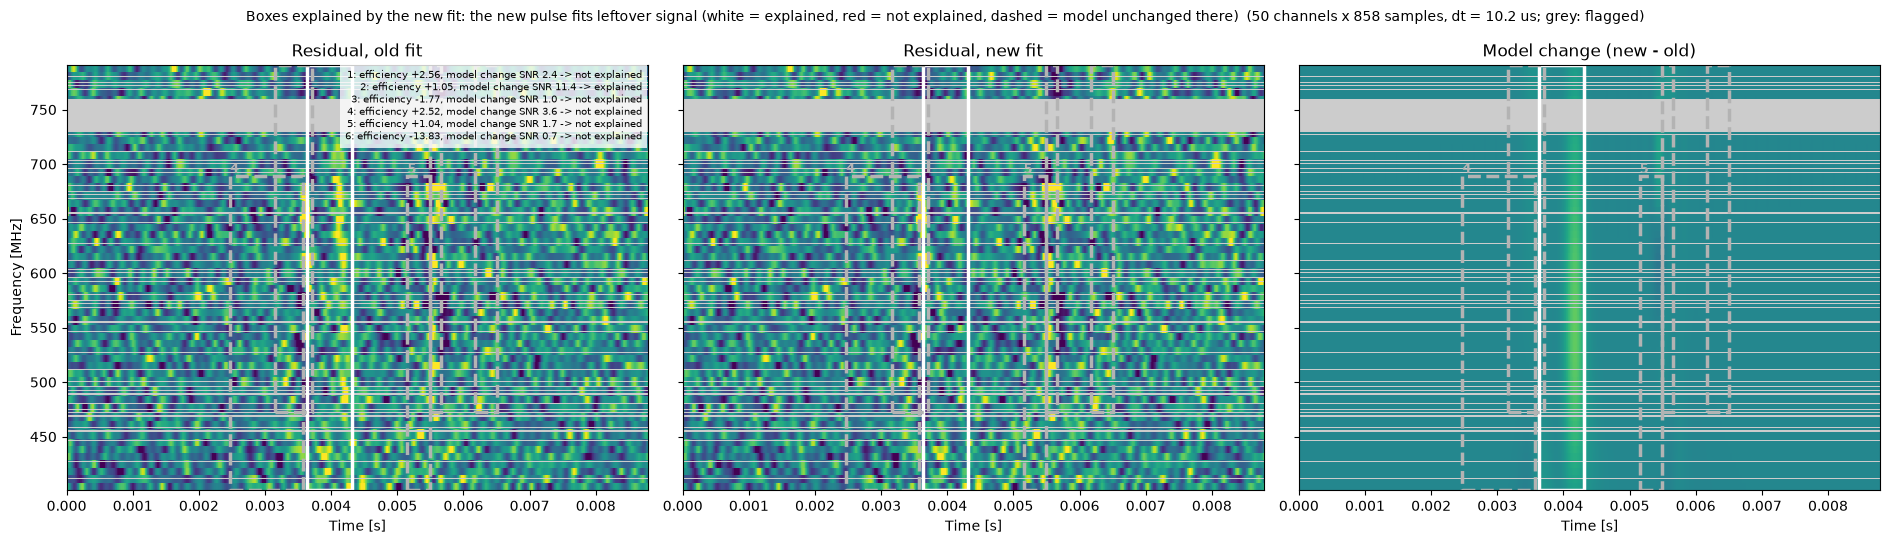

3 -> 4 pulses: delta ELPD = 86.8 (need 32.0), explains leftover signal: True -> accept
Residual test (tolerating 20% model error): ADD A PULSE (p = 1.3e-36 after 56240 boxes; min_snr 8)
  2394 boxes significant on their own, making 6 separate feature(s):
    3.16-4.26 ms, 476-788 MHz: unexplained SNR 21.0 (residual 21.8, model 29.1), centre 3.57 ms, width 0.10 ms
    5.49-5.66 ms, 404-788 MHz: unexplained SNR 14.1 (residual 15.1, model 26.5), centre 5.56 ms, width 0.06 ms
    0.00-3.29 ms + 7.69-8.79 ms (wraps), 476-788 MHz: unexplained SNR 20.8 (residual 22.0, model 35.6), centre 2.74 ms, width 0.68 ms
    5.15-5.49 ms, 404-686 MHz: unexplained SNR 13.1 (residual 14.9, model 35.5), centre 5.36 ms, width 0.14 ms
    6.17-6.50 ms, 476-788 MHz: unexplained SNR 11.6 (residual 11.8, model 8.7), centre 6.36 ms, width 0.15 ms
    5.63-5.90 ms, 515-579 MHz: unexplained SNR 8.1 (residual 8.5, model 13.3), centre 5.73 ms, width 0.09 ms
prior being set with bounds:
sigma_min = 2.6890819453714833

  0%|          | 0/700 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


sample: 100%|██████████| 700/700 [06:44<00:00,  1.73it/s]


group_chains: 64 chains -> 25 mode(s) (pairs linked where every R-hat < 1.1)
  mode 0: chains [1, 2, 3, 4, 5, 6, 7, 8, 9, 12, 13, 14, 15, 16, 17, 18, 20, 21, 22, 24, 25, 26, 28, 29, 30, 31, 37, 62], largest R-hat within 1.060
  mode 1: chains [11, 27], largest R-hat within 1.042
  mode 2: chains [41]
  mode 3: chains [10, 19], largest R-hat within 1.018
  mode 4: chains [23]
  mode 5: chains [0]
  mode 6: chains [61]
  mode 7: chains [42, 47], largest R-hat within 1.044
  mode 8: chains [52]
  mode 9: chains [32, 45, 46, 55], largest R-hat within 1.030
  mode 10: chains [36]
  mode 11: chains [60]
  mode 12: chains [44]
  mode 13: chains [57]
  mode 14: chains [33]
  mode 15: chains [39, 48, 49, 50, 54], largest R-hat within 1.059
  mode 16: chains [58]
  mode 17: chains [56]
  mode 18: chains [59]
  mode 19: chains [43]
  mode 20: chains [53]
  mode 21: chains [34, 51, 63], largest R-hat within 1.056
  mode 22: chains [38]
  mode 23: chains [40]
  mode 24: chains [35]
  modes weighted

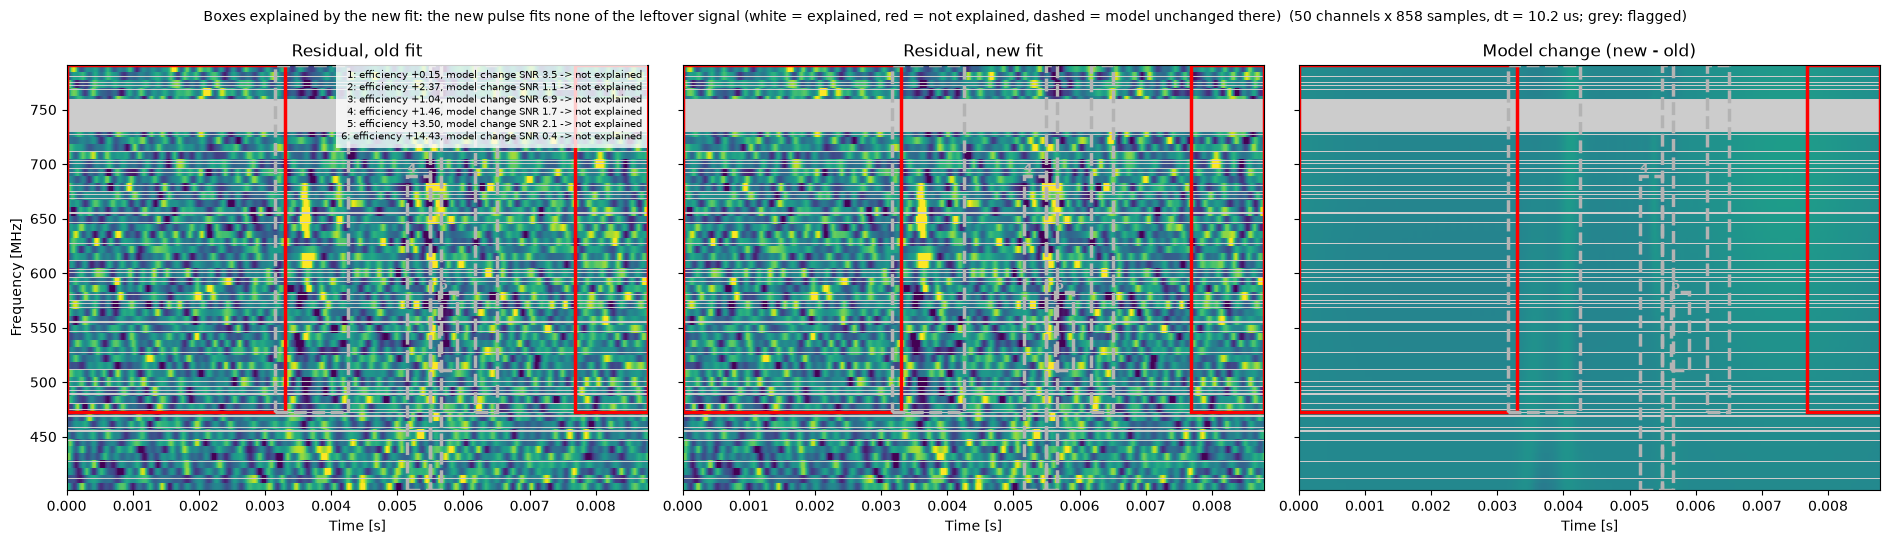

4 -> 5 pulses: delta ELPD = 23.7 (need 32.0), explains leftover signal: False -> reject
final: 4 pulses (5-pulse fit rejected: it explains no flagged leftover signal and delta ELPD 23.7 < 32)
rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


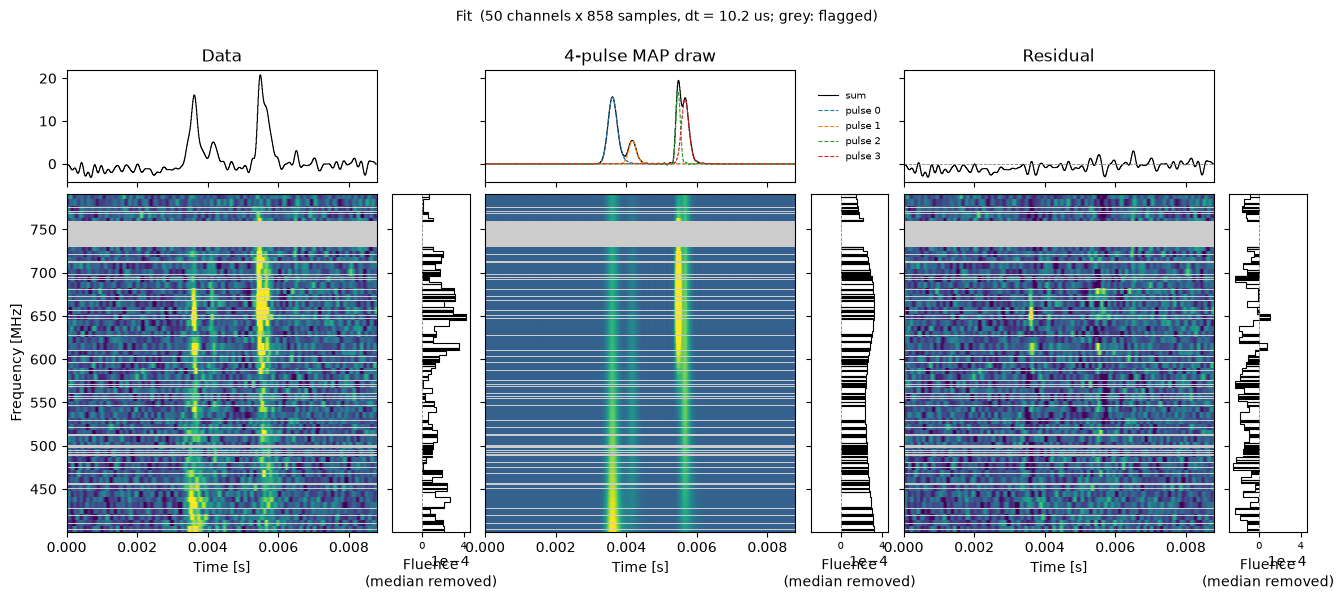

In [6]:
import numpyro.distributions as dist
from model import running_power_law_log_sed

constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
    "channel_width": burst.channel_width,
    "det_response": 1.0,           # beam response, set to 1 if not used
}

single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=running_power_law_log_sed,      # ln F = gamma x + beta x^2, no orthogonal basis
    fourier_freqs=burst.fourier_freqs,
)

result_gb = iterative_pulse_fit(
    burst, single_pulse_fn,
    snr_min=8.0,          # one detection SNR: search, box check, and delta ELPD >= snr_min^2 / 2
    n_max=5,              # largest number of pulses tried
    num_chains=64,
    seed=2,
    plot_steps=True,      # draw each step's box check (False to skip)
    prior_kwargs=dict(gamma=dist.Uniform(-10.0, 200.0),     # same box the c1, c2 bounds come from
                      beta=dist.Uniform(-200.0, 10.0)),
    repulsion={},         # passed to the likelihood
)

# the kept fit, drawn at its maximum a posteriori draw
n = result_gb["n_pulses"]
p = result_gb["fit"]["map"]
M, M_pulses = model_from_draw(single_pulse_fn, {k: np.asarray(v)[None] for k, v in p.items()}, 0)
plot_fit_TD(burst, M, M_pulses, title_model=f"{n}-pulse MAP draw");

# # save the kept fit
# idata = save_run(
#     out_path, result["fit"]["mcmc"], burst, result["fit"]["priors"], data_path,
#     single_pulse_fn=single_pulse_fn, event_id=event_id,
#     dm_dedispersion=dm_dedispersion, dedispersion_ref_freq=dedispersion_ref_freq,
#     n_pulses=n, itfit_snr_min=result["snr_min"], itfit_stop=result["stop"],
# )

In [27]:
from postprocess import order_pulses

n = result["n_pulses"]
post = order_pulses({k: np.asarray(v) for k, v in result["fit"]["post"].items()},
                    active_snr=None, verbose=False)               # every draw ordered by arrival time alone
info = result["fit"]["info"]

units = {"mean_arrival_time": ("arrival_time_ms", 1e3), "sigma": ("sigma_ms", 1e3),
         "tau_ref": ("tau_ref_us", 1e6)}

# regroup the pooled draws by their source chain, so R-hat and ESS can be computed
order = np.lexsort((info["draw"], info["chain"]))
chains, counts = np.unique(np.asarray(info["chain"])[order], return_counts=True)
by_chain = np.all(counts == counts[0])                            # False when several modes were subsampled
shape = (len(chains), counts[0]) if by_chain else (1, len(order))

data, dims = {}, {}
for k, v in post.items():
    if not k.endswith("_shared") and f"{k}_shared" in post:
        continue                                                  # copy of a shared parameter
    name, unit = units.get(k.removesuffix("_shared"), (k, 1.0))
    v = np.asarray(v, dtype=float)[order] * unit
    data[name] = v.reshape(shape + v.shape[1:])
    if v.ndim == 2 and v.shape[1] == n:
        dims[name] = ["pulse"]

dt_post = az.from_dict({"posterior": data}, dims=dims, coords={"pulse": np.arange(n)})
print(f"{len(chains)} chains x {counts[0]} draws" if by_chain else
      f"chains contributed unequal draws (several modes): summarized as one sequence of {len(order)} "
      f"draws, so R-hat is nan")
az.summary(dt_post, kind="all")

chains contributed unequal draws (several modes): summarized as one sequence of 571 draws, so R-hat is nan


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],8.92e-05,2.7e-06,8.4e-05,9.3e-05,286,185,nan,1.6e-07,1.3e-07
A[1],2.9e-05,3e-06,2.4e-05,3.4e-05,538,514,nan,1.3e-07,9.3e-08
A[2],4.5e-06,1.3e-06,2.8e-06,7e-06,198,37,nan,9.9e-08,7.6e-08
A[3],8.09e-05,3.3e-06,7.5e-05,8.6e-05,118,55,nan,3.1e-07,2e-07
A_snr[0],43.2,1,42,45,27,105,nan,0.19,0.051
A_snr[1],13.76,1.03,12,15,534,468,nan,0.045,0.037
A_snr[2],47.4,1.2,46,49,116,172,nan,0.11,0.06
A_snr[3],36.3,1.2,34,38,12,168,nan,0.38,0.069
DM_shared,-0.0048,0.0008,-0.0061,-0.0036,87,132,nan,8.3e-05,3.5e-05
beta[0],1.4,0.69,0.24,2.5,104,82,nan,0.069,0.036


In [28]:
from postprocess import order_pulses

n = result["n_pulses"]
info = result["fit"]["info"]
raw = order_pulses({k: np.asarray(v) for k, v in result["fit"]["mcmc"].get_samples(group_by_chain=True).items()},
                   active_snr=None, verbose=False)              # every draw ordered by arrival time alone

units = {"mean_arrival_time": ("arrival_time_ms", 1e3), "sigma": ("sigma_ms", 1e3),
         "tau_ref": ("tau_ref_us", 1e6)}

for m, (chains, w) in enumerate(zip(info["modes"], info["weights"])):
    data, dims = {}, {}
    for k, v in raw.items():
        if not k.endswith("_shared") and f"{k}_shared" in raw:
            continue                                              # copy of a shared parameter
        name, unit = units.get(k.removesuffix("_shared"), (k, 1.0))
        data[name] = np.asarray(v, dtype=float)[list(chains)] * unit
        if data[name].ndim == 3 and data[name].shape[2] == n:
            dims[name] = ["pulse"]
    dt_mode = az.from_dict({"posterior": data}, dims=dims, coords={"pulse": np.arange(n)})
    print(f"mode {m}: weight {w:.3g}, {len(chains)} chains x {data[name].shape[1]} draws")
    display(az.summary(dt_mode, kind="all"))

mode 0: weight 0.65, 13 chains x 200 draws


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],8.87e-05,3.2e-06,8.4e-05,9.4e-05,3454,2122,1.00,5.4e-08,6.4e-08
A[1],2.88e-05,3.1e-06,2.4e-05,3.4e-05,3682,2253,1.00,5e-08,6e-08
A[2],4.61e-06,1.36e-06,2.7e-06,7e-06,2267,2045,1.00,2.8e-08,2.6e-08
A[3],8.05e-05,3.6e-06,7.5e-05,8.6e-05,2487,1588,1.01,7.3e-08,7.4e-08
A_snr[0],42.9,0.99,41,44,3457,2242,1.00,0.017,0.019
A_snr[1],13.68,1.02,12,15,3517,2186,1.00,0.017,0.019
A_snr[2],47.36,1.28,45,49,2923,1912,1.00,0.024,0.024
A_snr[3],35.88,1.28,34,38,2473,1749,1.01,0.026,0.027
DM_shared,-0.00491,0.0008,-0.0062,-0.0036,3616,2149,1.01,1.3e-05,1.5e-05
beta[0],1.52,0.71,0.42,2.7,3139,1801,1.00,0.013,0.016


mode 1: weight 0.35, 1 chains x 200 draws


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],8.98e-05,1.9e-06,8.6e-05,9.3e-05,32,64,nan,3.4e-07,1.3e-07
A[1],2.92e-05,2.9e-06,2.4e-05,3.3e-05,122,135,nan,2.6e-07,1.6e-07
A[2],4.2e-06,9e-07,2.8e-06,5.5e-06,26,39,nan,1.7e-07,1.1e-07
A[3],8.19e-05,2.4e-06,7.8e-05,8.6e-05,38,27,nan,3.9e-07,3e-07
A_snr[0],43.7,0.8,42,45,21,30,nan,0.18,0.093
A_snr[1],13.8,1.1,12,15,162,92,nan,0.084,0.08
A_snr[2],47.5,0.9,46,49,4,7,nan,0.44,0.12
A_snr[3],36.9,0.8,36,38,37,23,nan,0.13,0.093
DM_shared,-0.0047,0.0008,-0.0061,-0.0035,11,19,nan,0.00022,9e-05
beta[0],1.3,0.7,0.09,2.4,14,31,nan,0.2,0.066


mode 2: weight 0, 16 chains x 200 draws


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],8.78e-05,3.2e-06,8.3e-05,9.3e-05,3650,2479,1.00,5.2e-08,5.1e-08
A[1],4.92e-06,1.35e-06,3e-06,7.3e-06,2863,2532,1.00,2.6e-08,2.4e-08
A[2],7.75e-05,3.4e-06,7.2e-05,8.3e-05,3568,2627,1.00,5.7e-08,5.6e-08
A[3],1.1e-06,2.2e-06,1.3e-10,6.3e-06,1328,1218,1.01,6.6e-08,8.3e-08
A_snr[0],42.74,0.99,41,44,3421,2415,1.00,0.017,0.016
A_snr[1],47.95,1.28,46,50,3401,2234,1.01,0.022,0.022
A_snr[2],34.88,1.23,33,37,3886,2706,1.00,0.02,0.021
A_snr[3],6.92,1.05,5.2,8.6,4186,2198,1.00,0.016,0.021
DM_shared,-0.00592,0.00075,-0.0071,-0.0047,3978,2588,1.00,1.2e-05,1.3e-05
beta[0],1.84,0.7,0.72,2.9,2708,2172,1.00,0.013,0.012


... (28 outputs left out)

mode 17: weight 0, 1 chains x 200 draws


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],3e-05,5e-05,9.4e-08,0.00012,7,44,nan,2.9e-05,1.2e-05
A[1],0.000121,2e-05,0.0001,0.00015,9,7,nan,4.7e-06,7.7e-06
A[2],0.0001,7e-05,6.8e-19,0.00016,7,24,nan,3.8e-05,1.7e-05
A[3],2e-05,2.2e-05,2.6e-08,6.1e-05,18,29,nan,5.5e-06,1.1e-06
A_snr[0],1.67e+01,19,2.2,46,6,6,nan,11,4.6
A_snr[1],49,7,43,60,4,21,nan,3.6,1.9
A_snr[2],4.22e+01,2.70e+01,0.51,62,5,34,nan,16,6.6
A_snr[3],6.6,1.8,3.8,8.9,28,46,nan,0.31,0.24
DM_shared,-0.0037,0.0008,-0.0049,-0.0024,55,44,nan,0.00011,6.7e-05
beta[0],-1.05e+02,7.57e+01,-190,2.3,5,12,nan,41,15


mode 18: weight 0, 1 chains x 200 draws


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],3e-11,7e-11,1e-13,1.1e-10,71,91,nan,5.5e-12,1e-11
A[1],0.000437,3.2e-05,0.00039,0.00049,76,45,nan,3.8e-06,3.1e-06
A[2],1.6e-08,4e-08,7.2e-10,6.3e-08,72,118,nan,4e-09,1.3e-08
A[3],5e-07,1.6e-06,2.1e-11,2e-06,63,46,nan,1.7e-07,3.7e-07
A_snr[0],21.8,3.7,17,28,84,74,nan,0.42,0.31
A_snr[1],45.8,3,42,51,61,47,nan,0.49,0.56
A_snr[2],1.57,0.12,1.4,1.8,288,168,nan,0.007,0.0081
A_snr[3],20,4,13,27,47,45,nan,0.69,0.58
DM_shared,-0.107,0.015,-0.13,-0.081,71,52,nan,0.0019,0.0017
beta[0],-164,23,-200,-120,54,48,nan,3,1


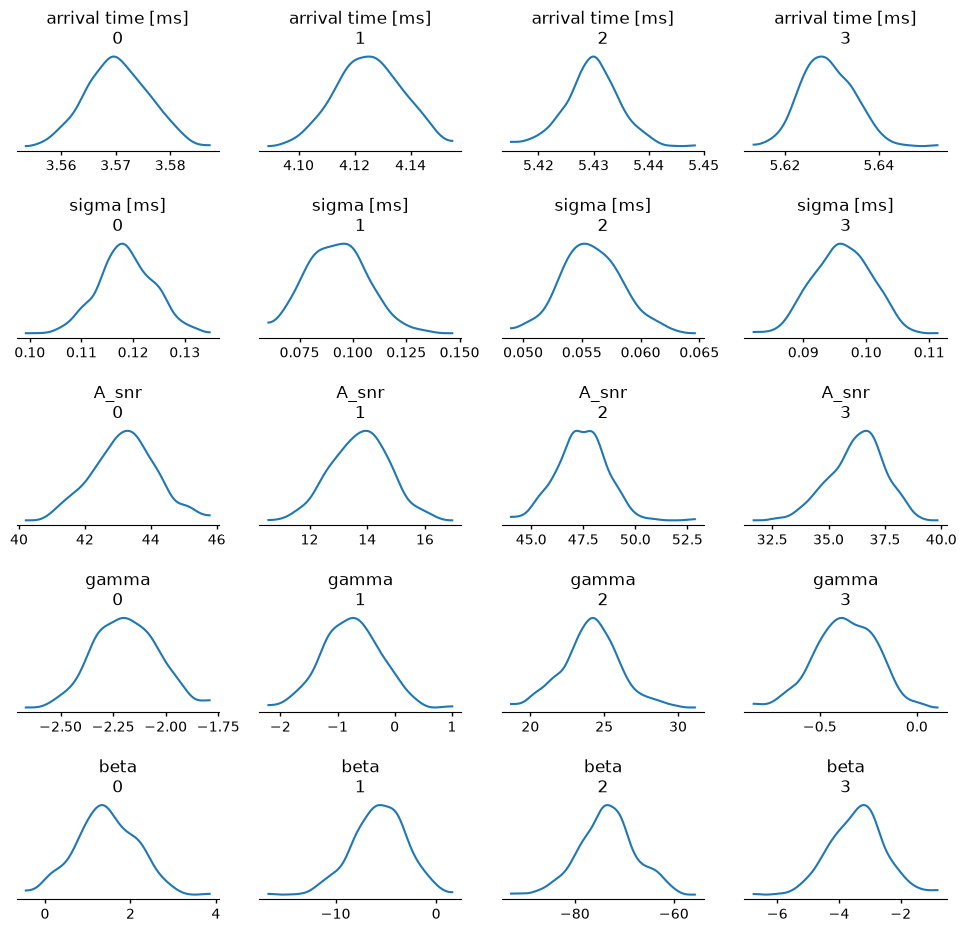

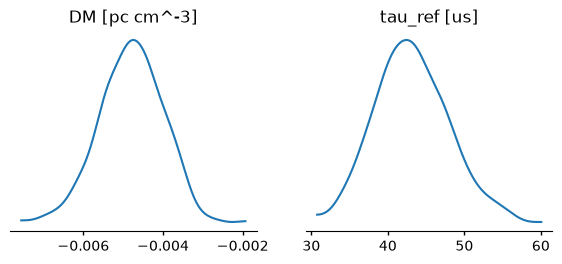

In [9]:
import arviz as az
import arviz_plots as azp
import matplotlib.pyplot as plt
from postprocess import order_pulses

n = result["n_pulses"]
post = order_pulses({k: np.asarray(v) for k, v in result["fit"]["post"].items()},
                    active_snr=None, verbose=False)          # every draw ordered by arrival time alone

# variable: (label, unit factor); only those present in the posterior are plotted
per_pulse = {"mean_arrival_time": ("arrival time [ms]", 1e3), "sigma": ("sigma [ms]", 1e3),
             "A_snr": ("A_snr", 1.0), "gamma": ("gamma", 1.0), "beta": ("beta", 1.0)}
shared = {"DM": ("DM [pc cm^-3]", 1.0), "tau_ref": ("tau_ref [us]", 1e6), "delta": ("delta", 1.0)}

data, pulse_vars, shared_vars = {}, [], []
for k, (label, unit) in per_pulse.items():
    if k in post:
        data[label] = (np.asarray(post[k], dtype=float).reshape(-1, n) * unit)[None]   # (chain, draw, pulse)
        pulse_vars.append(label)
for k, (label, unit) in shared.items():
    src = f"{k}_shared" if f"{k}_shared" in post else (k if k in post else None)
    if src is not None:
        v = np.asarray(post[src], dtype=float)
        data[label] = (v.reshape(v.shape[0], -1)[:, 0] * unit)[None]                  # (chain, draw)
        shared_vars.append(label)

# the pooled draws are treated as one chain
dt = az.from_dict({"posterior": data}, dims={v: ["pulse"] for v in pulse_vars}, coords={"pulse": np.arange(n)})
density_only = {"credible_interval": False, "point_estimate": False, "point_estimate_text": False}

# per-pulse posteriors: one row per parameter, one column per pulse (earliest first)
azp.plot_dist(dt, var_names=pulse_vars, cols=["__variable__", "pulse"], col_wrap=n, visuals=density_only,
              figure_kwargs={"figsize": (3 * n, 2.2 * len(pulse_vars))})
plt.gcf().subplots_adjust(hspace=0.9)
plt.show()

# parameters shared by every pulse
azp.plot_dist(dt, var_names=shared_vars, visuals=density_only,
              figure_kwargs={"figsize": (3.5 * len(shared_vars), 2.6)})
plt.show()

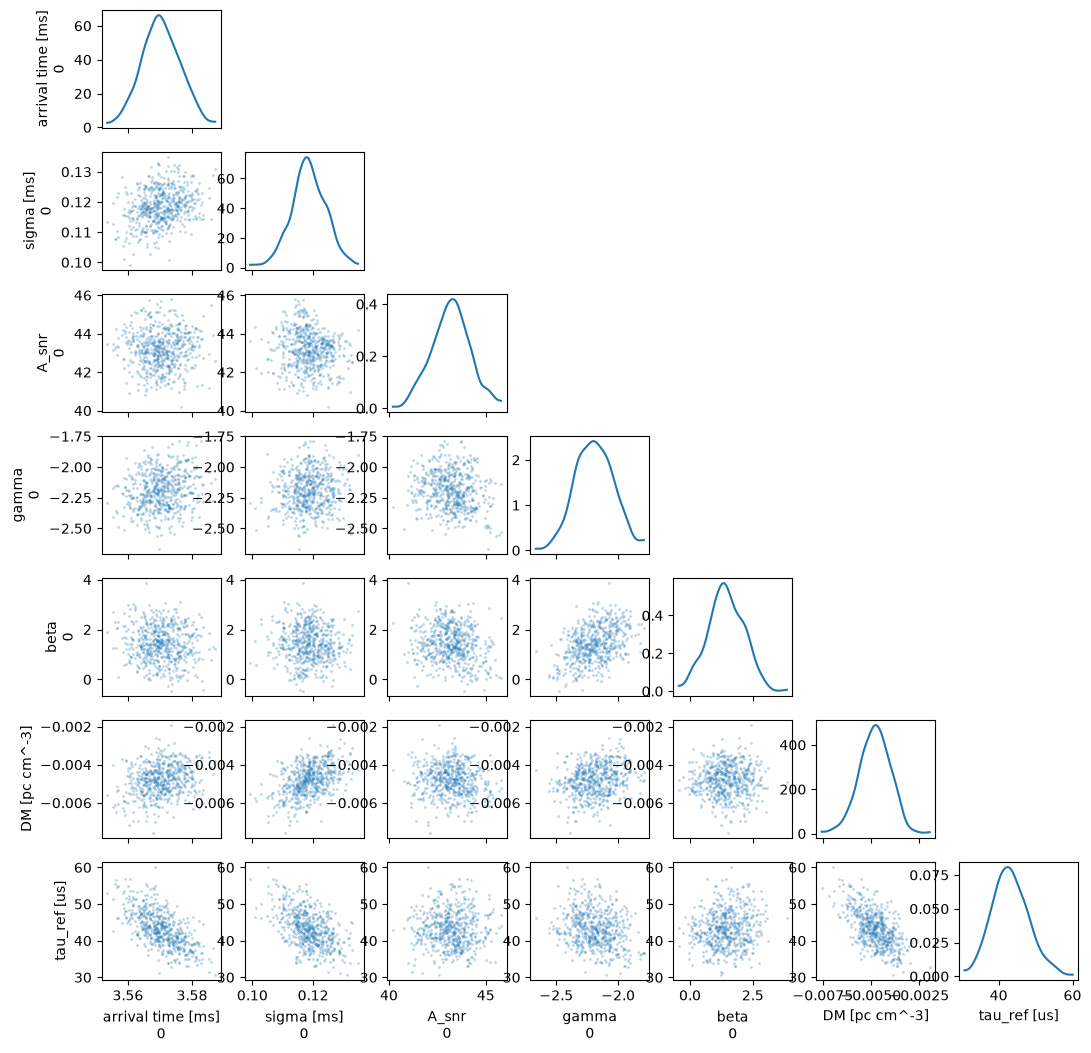

In [24]:
import arviz_base
arviz_base.rcParams["plot.max_subplots"] = 300      # the default limit (40) is too small for a corner plot

PULSE = 0                                  # which pulse (0 = earliest)
names = pulse_vars + shared_vars
azp.plot_pair(dt, var_names=names, coords={"pulse": [PULSE]}, marginal=True, triangle="lower",
              visuals={**density_only, "scatter": {"alpha": 0.3, "size": 4}},
              figure_kwargs={"figsize": (1.8 * len(names), 1.8 * len(names))})
plt.show()

plotting 12 variables: ['A', 'A_snr', 'DM [pc cm^-3]', 'beta', 'c1', 'c2', 'gamma', 'log_sed_peak', 'arrival time [ms]', 'sigma [ms]', 'snr_opt', 'tau_ref [us]']
not plotted: ['toa_separation']


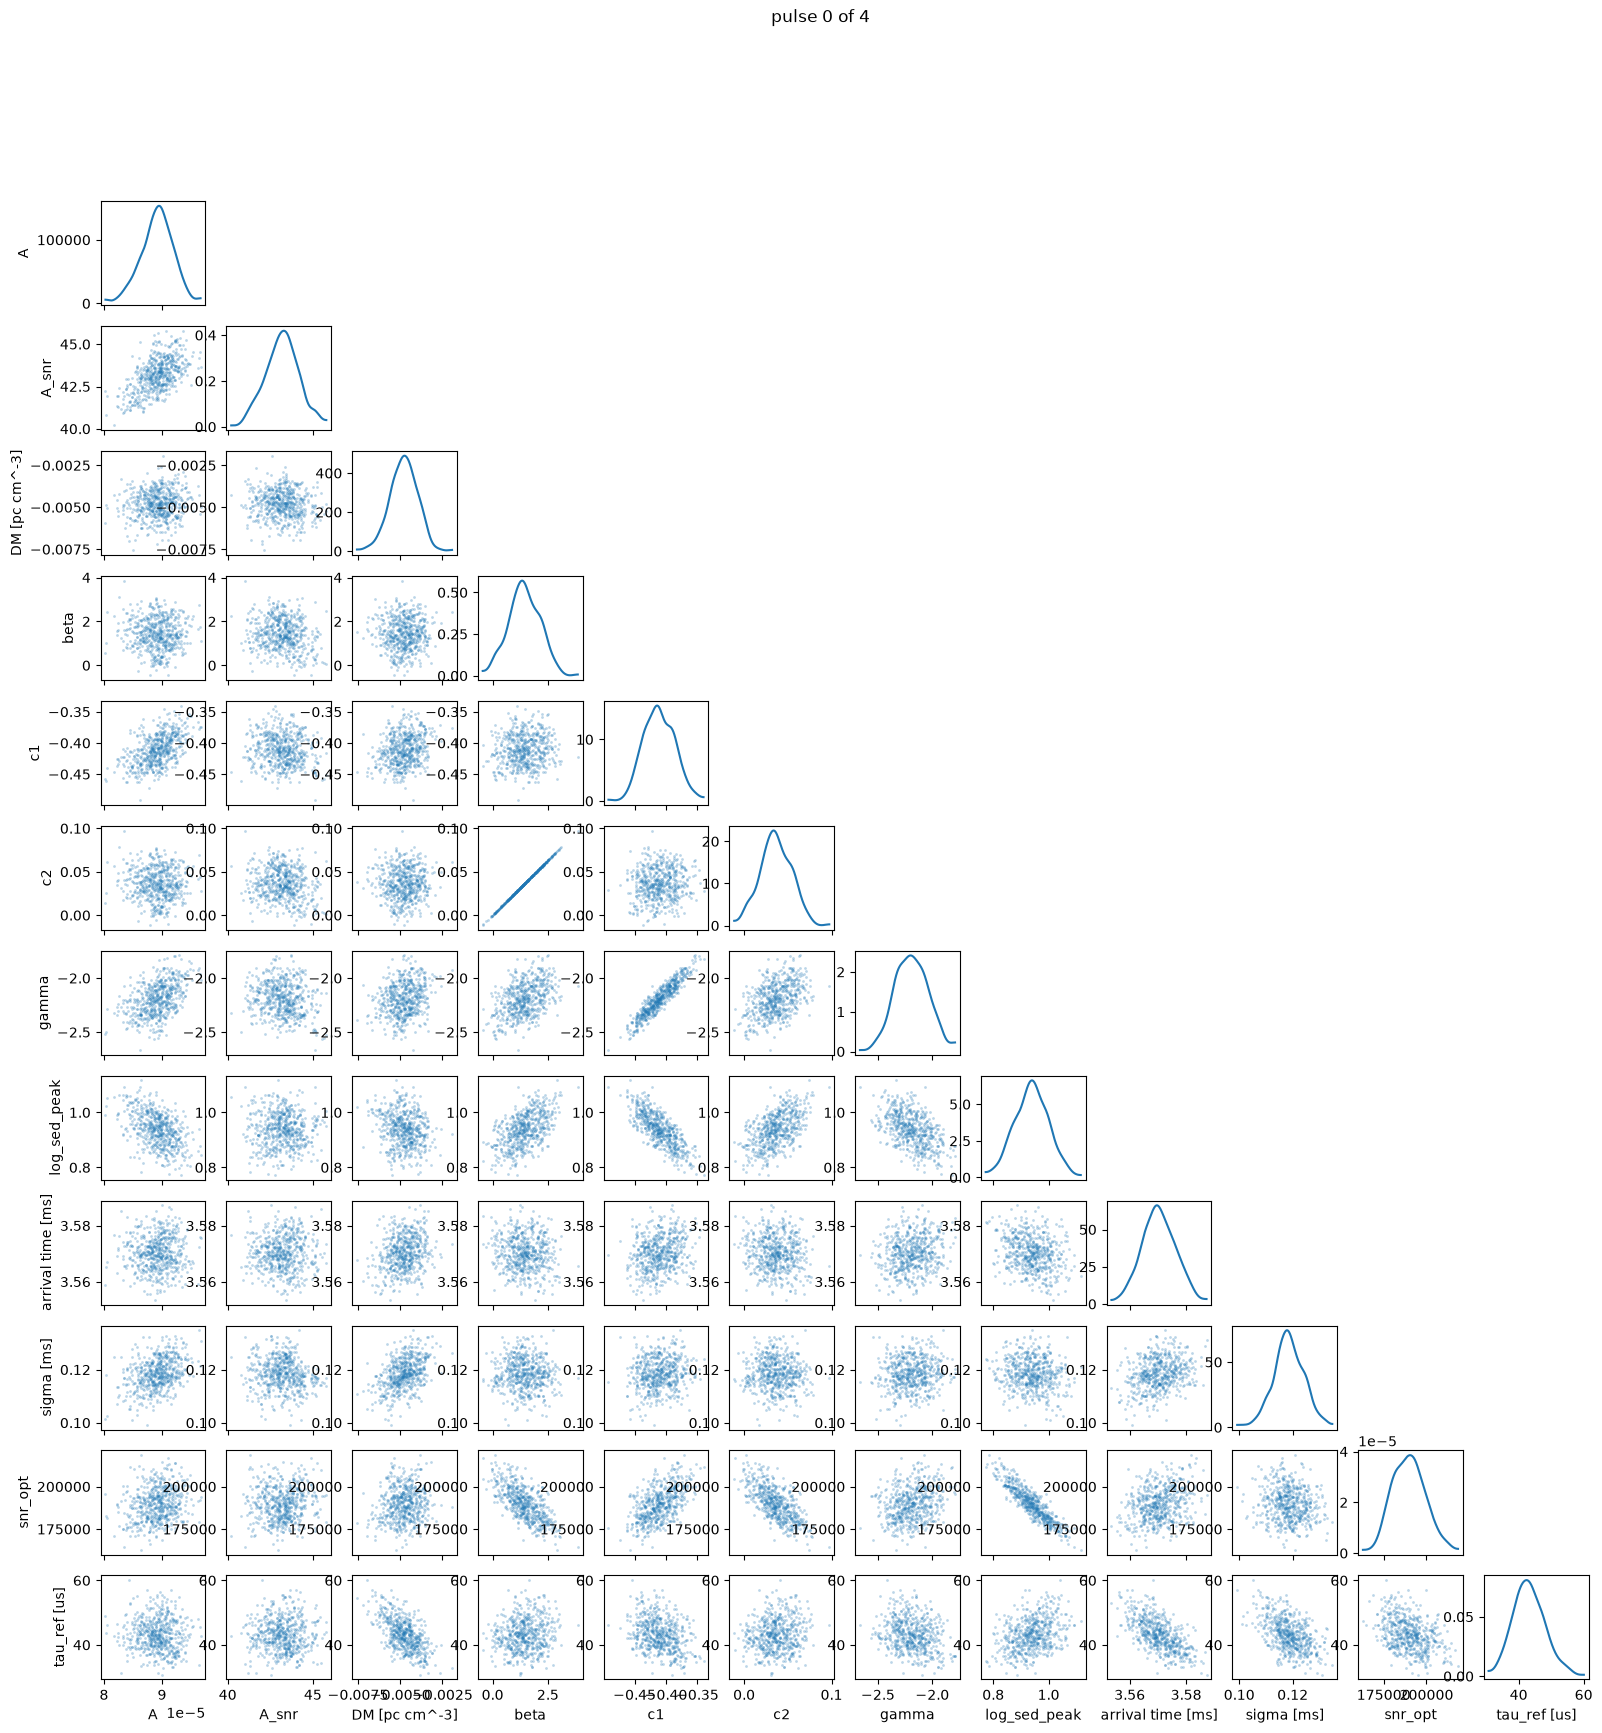

In [25]:
import arviz as az
import arviz_plots as azp
import arviz_base
from postprocess import order_pulses

PULSE = 0                                                   # which pulse (0 = earliest)
n = result["n_pulses"]
post = order_pulses({k: np.asarray(v) for k, v in result["fit"]["post"].items()},
                    active_snr=None, verbose=False)          # every draw ordered by arrival time alone

units = {"mean_arrival_time": ("arrival time [ms]", 1e3), "sigma": ("sigma [ms]", 1e3),
         "tau_ref": ("tau_ref [us]", 1e6), "DM": ("DM [pc cm^-3]", 1.0)}
data, skipped = {}, []
for k, v in post.items():
    if not k.endswith("_shared") and f"{k}_shared" in post:
        continue                                             # copy of a shared parameter
    v = np.asarray(v, dtype=float)
    if v.ndim == 1:
        x = v                                                # shared: one value per draw
    elif v.ndim == 2 and v.shape[1] == n:
        x = v[:, PULSE]                                      # this pulse's value
    else:
        skipped.append(k)                                    # e.g. per-pair separations
        continue
    if not np.all(np.isfinite(x)) or np.std(x) == 0:
        skipped.append(k)                                    # constant: nothing to plot
        continue
    label, unit = units.get(k.removesuffix("_shared"), (k.removesuffix("_shared"), 1.0))
    data[label] = (x * unit)[None]                           # (chain, draw)
print(f"plotting {len(data)} variables:", list(data))
if skipped:
    print("not plotted:", skipped)

dt_pulse = az.from_dict({"posterior": data})
arviz_base.rcParams["plot.max_subplots"] = max(1000, len(data) ** 2)
pc = azp.plot_pair(dt_pulse, var_names=list(data), marginal=True, triangle="lower",
                   visuals={"credible_interval": False, "point_estimate": False, "point_estimate_text": False,
                            "scatter": {"alpha": 0.3, "size": 4}},
                   figure_kwargs={"figsize": (1.6 * len(data), 1.6 * len(data))})
pc.add_title(f"pulse {PULSE} of {n}")
pc.show()

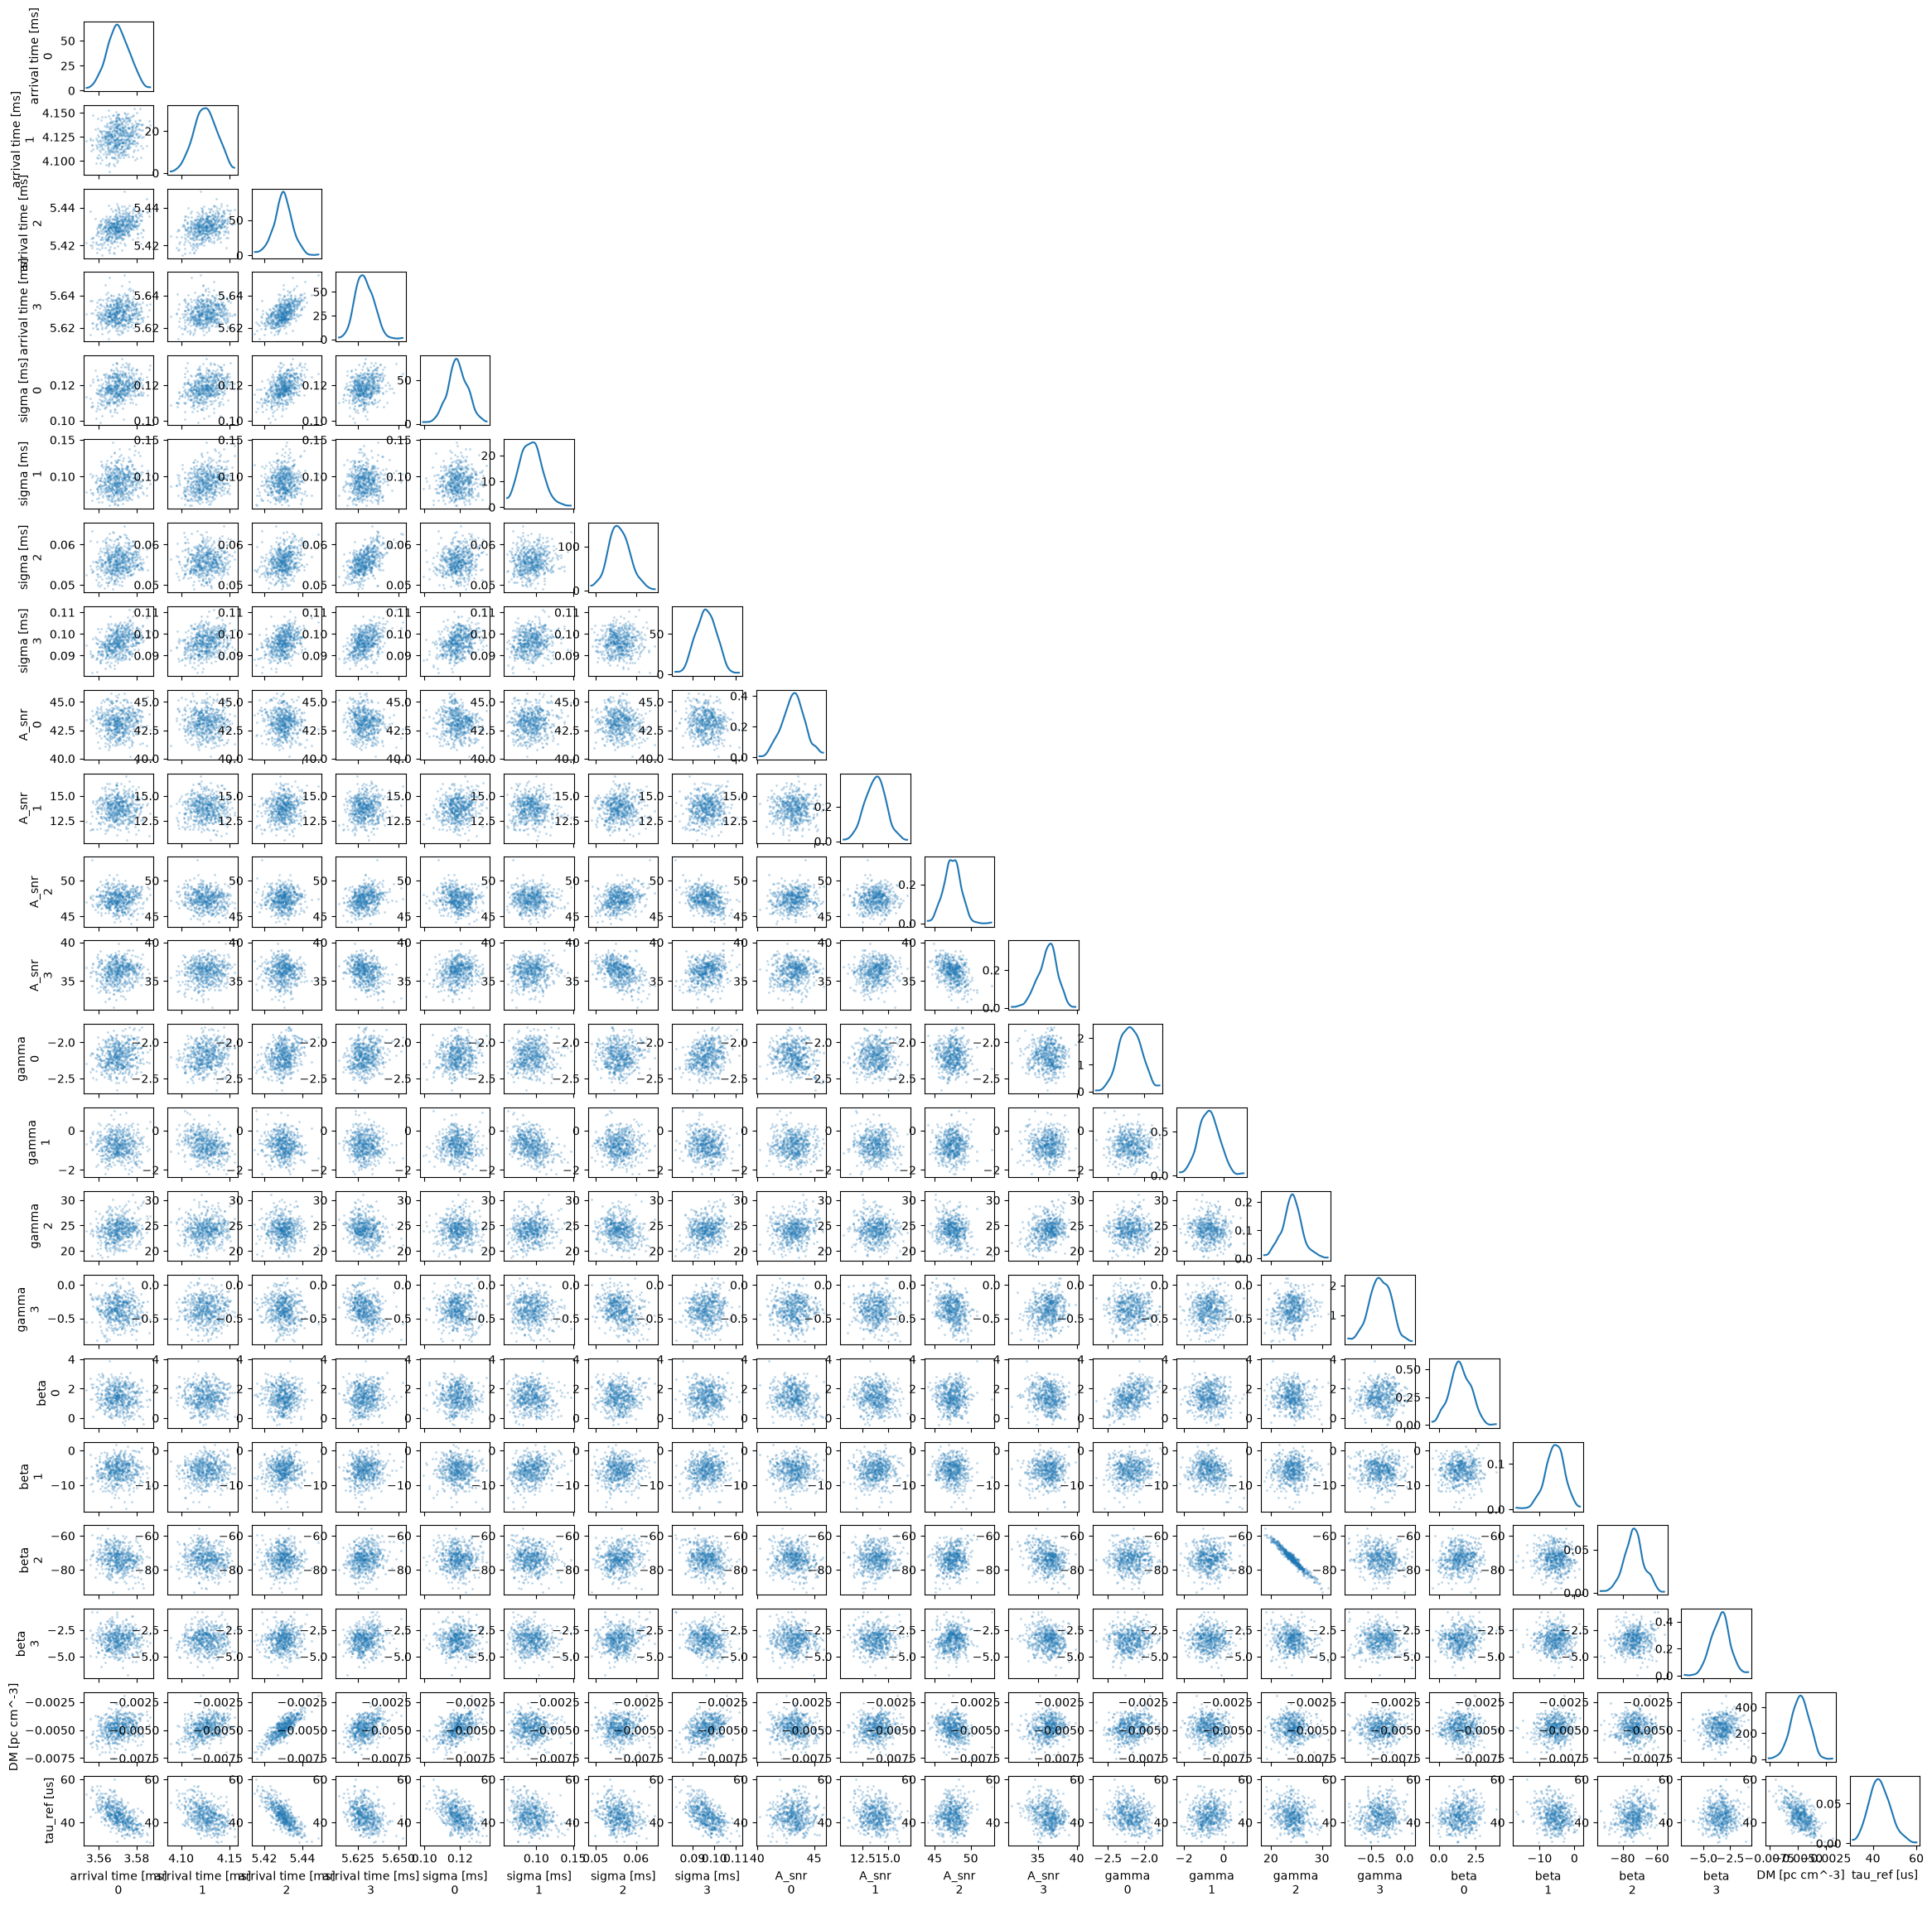

In [11]:
import arviz_base
arviz_base.rcParams["plot.max_subplots"] = 1000     # the default limit (40) is far too small for this

names = pulse_vars + shared_vars                    # trim this list to shrink the grid
n_axes = len([v for v in names if v in pulse_vars]) * n + len([v for v in names if v in shared_vars])
azp.plot_pair(dt, var_names=names, marginal=True, triangle="lower",
              visuals={**density_only, "scatter": {"alpha": 0.3, "size": 4}},
              figure_kwargs={"figsize": (1.3 * n_axes, 1.3 * n_axes)})
plt.show()